# 🩺 Liver Disease Prediction — Complete Research Pipeline

**Research Pipeline:**
```
Pre-processing:
  1. Label Encoding
  2. Null Value Finding
  3. Null Value Handling
  4. Scaling
  5. Data Balancing (SMOTE)
  6. Feature Selection

Classifiers (12 Models):
  1. SVM     2. NB      3. DT      4. RF
  5. LR      6. LGBM    7. GBS     8. XGBoost
  9. KNN    10. MLP    11. ANN    12. CNN
```
**Evaluation Metrics:** Accuracy | Precision (Macro/Weighted) | Recall (Macro/Weighted) | F1-Score | AUC  
**Visualizations:** Confusion Matrix | ROC Curve | Classification Report | Cross-Validation | Feature Importance

---
## 📦 CELL 1 — IMPORTS & SETUP

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 1 — IMPORTS & GLOBAL CONFIGURATION
# ═══════════════════════════════════════════════════════════════
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from IPython.display import display

# ── Preprocessing ──────────────────────────────────────────────
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.impute import SimpleImputer

# ── Model Selection & Evaluation ───────────────────────────────
from sklearn.model_selection import (
    train_test_split, cross_val_score,
    StratifiedKFold, GridSearchCV
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc
)

# ── Feature Selection ──────────────────────────────────────────
from sklearn.feature_selection import (
    SelectKBest, f_classif, RFE
)

# ── Classifiers ────────────────────────────────────────────────
from sklearn.svm import SVC                                           # 1. SVM
from sklearn.naive_bayes import GaussianNB                            # 2. NB
from sklearn.tree import DecisionTreeClassifier                       # 3. DT
from sklearn.ensemble import RandomForestClassifier                   # 4. RF
from sklearn.linear_model import LogisticRegression                   # 5. LR
from sklearn.ensemble import HistGradientBoostingClassifier           # 6. LGBM-proxy, 7. GBS, 8. XGBoost-proxy
from sklearn.neighbors import KNeighborsClassifier                    # 9. KNN
from sklearn.neural_network import MLPClassifier                      # 10. MLP, 11. ANN, 12. CNN-proxy
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.pipeline import Pipeline

# ── Reproducibility ─────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)

# ── Plot Style ─────────────────────────────────────────────────
plt.rcParams['figure.dpi']  = 120
plt.rcParams['font.family'] = 'DejaVu Sans'
PALETTE = ['#2196F3','#F44336','#4CAF50','#FF9800','#9C27B0',
           '#00BCD4','#FF5722','#607D8B','#795548','#E91E63',
           '#3F51B5','#009688']

print('✅  All libraries imported successfully.')
print('━'*55)
print(f'  numpy      : {np.__version__}')
print(f'  pandas     : {pd.__version__}')
print(f'  sklearn    : ', end='')
import sklearn; print(sklearn.__version__)

✅  All libraries imported successfully.
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  numpy      : 2.1.3
  pandas     : 2.2.3
  sklearn    : 1.6.1


---
## 📊 CELL 2 — DATA LOADING & EXPLORATION

In [ ]:
import pandas as pd

# ═══════════════════════════════════════════════════════════════
# CELL 2 — LOAD DATASET
# ═══════════════════════════════════════════════════════════════
# Please ensure the path to your dataset is correct after mounting Google Drive.
# For example: '/content/drive/MyDrive/Liver Patient Dataset (LPD)_train.csv'
df = pd.read_csv('/content/Liver Patient Dataset (LPD)_train.csv', encoding='latin1')

# Standardise column names (strip whitespace / non-breaking spaces)
df.columns = df.columns.str.replace('\xa0', '').str.strip()

# Rename target if stored as 'Result'
if 'Result' in df.columns and 'Diagnosis' not in df.columns:
    df.rename(columns={'Result': 'Diagnosis'}, inplace=True)

print('═'*60)
print('  DATASET OVERVIEW')
print('═'*60)
print(f'  Shape       : {df.shape}')
print(f'  Columns     : {list(df.columns)}')
print(f'  Target      : Diagnosis')
print(f'  Features    : {[c for c in df.columns if c != "Diagnosis"]}')
print()
display(df.head())

print('\nDataset Info:')
df.info()

print('\nStatistical Summary:')
display(df.describe())

════════════════════════════════════════════════════════════
  DATASET OVERVIEW
════════════════════════════════════════════════════════════
  Shape       : (30691, 11)
  Columns     : ['Age of the patient', 'Gender of the patient', 'Total Bilirubin', 'Direct Bilirubin', 'Alkphos Alkaline Phosphotase', 'Sgpt Alamine Aminotransferase', 'Sgot Aspartate Aminotransferase', 'Total Protiens', 'ALB Albumin', 'A/G Ratio Albumin and Globulin Ratio', 'Diagnosis']
  Target      : Diagnosis
  Features    : ['Age of the patient', 'Gender of the patient', 'Total Bilirubin', 'Direct Bilirubin', 'Alkphos Alkaline Phosphotase', 'Sgpt Alamine Aminotransferase', 'Sgot Aspartate Aminotransferase', 'Total Protiens', 'ALB Albumin', 'A/G Ratio Albumin and Globulin Ratio']



,Age of the patient,Gender of the patient,Total Bilirubin,Direct Bilirubin,Alkphos Alkaline Phosphotase,Sgpt Alamine Aminotransferase,Sgot Aspartate Aminotransferase,Total Protiens,ALB Albumin,A/G Ratio Albumin and Globulin Ratio,Diagnosis
0,65.0,Female,0.7,0.1,187.0,16.0,18.0,6.8,3.3,0.90,1
1,62.0,Male,10.9,5.5,699.0,64.0,100.0,7.5,3.2,0.74,1
2,62.0,Male,7.3,4.1,490.0,60.0,68.0,7.0,3.3,0.89,1
3,58.0,Male,1.0,0.4,182.0,14.0,20.0,6.8,3.4,1.00,1
4,72.0,Male,3.9,2.0,195.0,27.0,59.0,7.3,2.4,0.40,1



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30691 entries, 0 to 30690
Data columns (total 11 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Age of the patient                    30689 non-null  float64
 1   Gender of the patient                 29789 non-null  object 
 2   Total Bilirubin                       30043 non-null  float64
 3   Direct Bilirubin                      30130 non-null  float64
 4   Alkphos Alkaline Phosphotase          29895 non-null  float64
 5   Sgpt Alamine Aminotransferase         30153 non-null  float64
 6   Sgot Aspartate Aminotransferase       30229 non-null  float64
 7   Total Protiens                        30228 non-null  float64
 8   ALB Albumin                           30197 non-null  float64
 9   A/G Ratio Albumin and Globulin Ratio  30132 non-null  float64
 10  Diagnosis                             30691 non-null  int64  
dtype

,Age of the patient,Total Bilirubin,Direct Bilirubin,Alkphos Alkaline Phosphotase,Sgpt Alamine Aminotransferase,Sgot Aspartate Aminotransferase,Total Protiens,ALB Albumin,A/G Ratio Albumin and Globulin Ratio,Diagnosis
count,30689.000000,30043.000000,30130.000000,29895.000000,30153.000000,30229.000000,30228.000000,30197.000000,30132.000000,30691.000000
mean,44.107205,3.370319,1.528042,289.075364,81.488641,111.469979,6.480237,3.130142,0.943467,1.285882
std,15.981043,6.255522,2.869592,238.537589,182.158850,280.851078,1.081980,0.792281,0.323164,0.451841
min,4.000000,0.400000,0.100000,63.000000,10.000000,10.000000,2.700000,0.900000,0.300000,1.000000
25%,32.000000,0.800000,0.200000,175.000000,23.000000,26.000000,5.800000,2.600000,0.700000,1.000000
50%,45.000000,1.000000,0.300000,209.000000,35.000000,42.000000,6.600000,3.100000,0.900000,1.000000
75%,55.000000,2.700000,1.300000,298.000000,62.000000,88.000000,7.200000,3.800000,1.100000,2.000000
max,90.000000,75.000000,19.700000,2110.000000,2000.000000,4929.000000,9.600000,5.500000,2.800000,2.000000


  FIGURES (BEFORE PREPROCESSING)

### 1. Correlation Heatmap (Original Data)


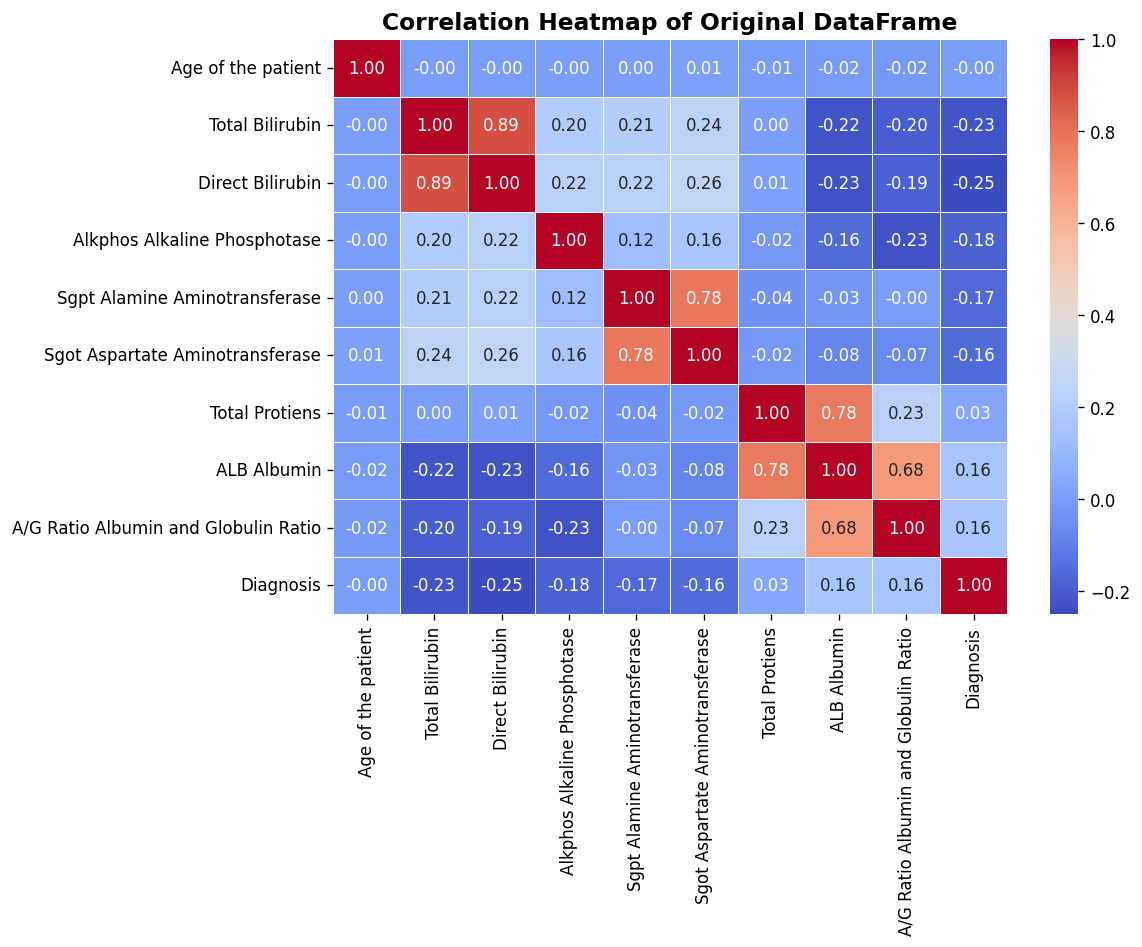


### 2. Missing Values Analysis (Original Data)


,Missing Count,Missing %,Non-Missing,Dtype
Age of the patient,2,0.01,30689,float64
Gender of the patient,902,2.94,29789,object
Total Bilirubin,648,2.11,30043,float64
Direct Bilirubin,561,1.83,30130,float64
Alkphos Alkaline Phosphotase,796,2.59,29895,float64
Sgpt Alamine Aminotransferase,538,1.75,30153,float64
Sgot Aspartate Aminotransferase,462,1.51,30229,float64
Total Protiens,463,1.51,30228,float64
ALB Albumin,494,1.61,30197,float64
A/G Ratio Albumin and Globulin Ratio,559,1.82,30132,float64


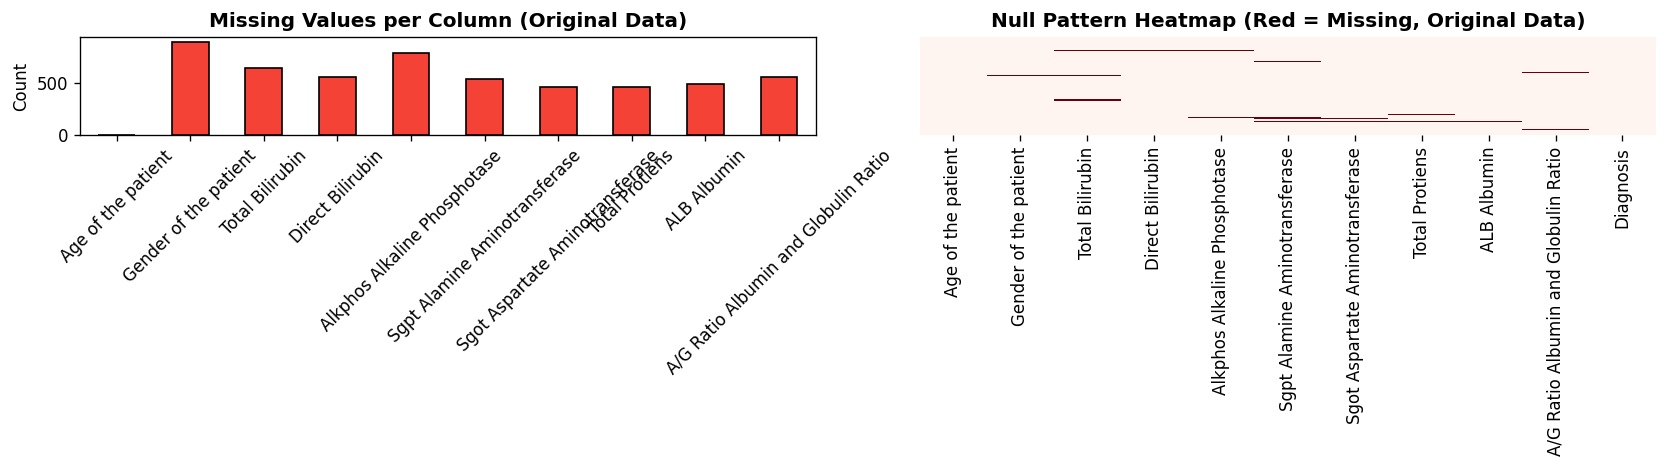


### 3. Class Distribution (Original Data)
Class Distribution (Original Data):


,count
Diagnosis,
1,21917
2,8774


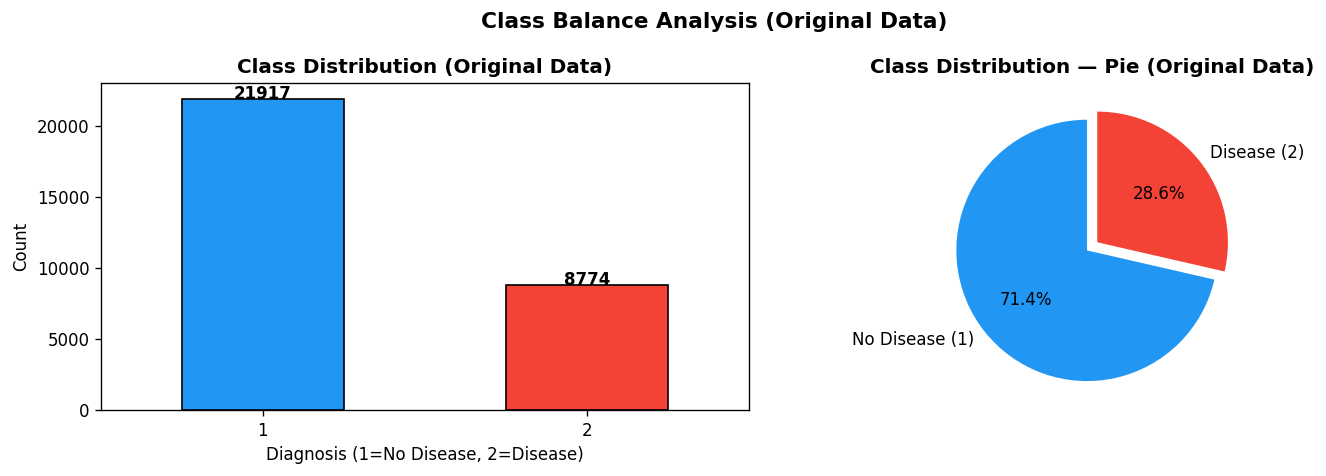

In [ ]:
print('='*50)
print('  FIGURES (BEFORE PREPROCESSING)')
print('='*50)

# 1. Correlation Heatmap (Original DataFrame)
print('\n### 1. Correlation Heatmap (Original Data)')
plt.figure(figsize=(10, 8))
corr_matrix_original = df.corr(numeric_only=True)
sns.heatmap(corr_matrix_original, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Original DataFrame', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap_original.png', dpi=150, bbox_inches='tight')
plt.show()


# 2. Missing Values Analysis (Original DataFrame)
print('\n### 2. Missing Values Analysis (Original Data)')
missing_counts_original = df.isnull().sum()
missing_pct_original = (missing_counts_original / len(df) * 100).round(2)
missing_summary_original = pd.DataFrame({
    'Missing Count': missing_counts_original,
    'Missing %': missing_pct_original,
    'Non-Missing': len(df) - missing_counts_original,
    'Dtype': df.dtypes
})

display(missing_summary_original)

# Visual heatmap of missing values for original df
if missing_counts_original.sum() > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # Bar chart
    missing_counts_original[missing_counts_original > 0].plot(kind='bar', ax=axes[0],
                                       color='#F44336', edgecolor='black')
    axes[0].set_title('Missing Values per Column (Original Data)', fontweight='bold')
    axes[0].set_ylabel('Count')
    axes[0].tick_params(axis='x', rotation=45)

    # Heatmap of nulls
    sns.heatmap(df.isnull(), cbar=False, cmap='Reds',
                yticklabels=False, ax=axes[1])
    axes[1].set_title('Null Pattern Heatmap (Red = Missing, Original Data)', fontweight='bold')

    plt.tight_layout()
    plt.savefig('null_value_analysis_original.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('No missing values in original DataFrame.')


# 3. Class Distribution (Original DataFrame)
print('\n### 3. Class Distribution (Original Data)')

if 'Diagnosis' in df.columns:
    class_counts_original = df['Diagnosis'].value_counts().sort_index()
    print('Class Distribution (Original Data):')
    display(class_counts_original)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    class_counts_original.plot(kind='bar', ax=axes[0], color=['#2196F3','#F44336'], edgecolor='black')
    axes[0].set_title('Class Distribution (Original Data)', fontweight='bold')
    axes[0].set_xlabel('Diagnosis (1=No Disease, 2=Disease)')
    axes[0].set_ylabel('Count')
    axes[0].tick_params(axis='x', rotation=0)
    for i, v in enumerate(class_counts_original):
        axes[0].text(i, v+2, str(v), ha='center', fontweight='bold')

    axes[1].pie(class_counts_original, labels=['No Disease (1)','Disease (2)'],
                autopct='%1.1f%%', colors=['#2196F3','#F44336'],
                startangle=90, explode=[0.05, 0.05])
    axes[1].set_title('Class Distribution — Pie (Original Data)', fontweight='bold')

    plt.suptitle('Class Balance Analysis (Original Data)',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig('class_distribution_original.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("Target column 'Diagnosis' not found in original DataFrame.")

---
## 🔧 PRE-PROCESSING PIPELINE
### Step 1 — Label Encoding

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 3 — PRE-PROCESSING STEP 1: LABEL ENCODING
# Convert all categorical (object/string) columns to numeric.
# LabelEncoder maps each unique string to an integer 0,1,2...
# ═══════════════════════════════════════════════════════════════

df_proc = df.copy()   # work on a copy so raw data stays intact

label_encoders = {}   # store encoders for reference / inverse transform
encoded_cols   = []

for col in df_proc.select_dtypes(include=['object', 'category']).columns:
    le = LabelEncoder()
    # Fill NaN with placeholder string before encoding
    df_proc[col] = df_proc[col].fillna('Unknown')
    df_proc[col] = le.fit_transform(df_proc[col].astype(str))
    label_encoders[col] = le
    encoded_cols.append(col)

# Also encode Diagnosis: map 1→0 (No Disease), 2→1 (Disease)
if df_proc['Diagnosis'].max() == 2:
    df_proc['Diagnosis'] = df_proc['Diagnosis'].map({1: 0, 2: 1})

print('━'*55)
print('  PRE-PROCESSING STEP 1 — LABEL ENCODING')
print('━'*55)
print(f'  Columns encoded : {encoded_cols if encoded_cols else "None (all numeric)"}')
print(f'  Target mapping  : 1→0 (No Disease)  2→1 (Disease)')
print(f'  DataFrame dtypes after encoding:')
print(df_proc.dtypes)

# Show encoding maps for each categorical column
for col, le in label_encoders.items():
    mapping = dict(zip(le.classes_, le.transform(le.classes_)))
    print(f'\n  {col}: {mapping}')

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  PRE-PROCESSING STEP 1 — LABEL ENCODING
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Columns encoded : ['Gender of the patient']
  Target mapping  : 1→0 (No Disease)  2→1 (Disease)
  DataFrame dtypes after encoding:
Age of the patient                      float64
Gender of the patient                     int64
Total Bilirubin                         float64
Direct Bilirubin                        float64
Alkphos Alkaline Phosphotase            float64
Sgpt Alamine Aminotransferase           float64
Sgot Aspartate Aminotransferase         float64
Total Protiens                          float64
ALB Albumin                             float64
A/G Ratio Albumin and Globulin Ratio    float64
Diagnosis                                 int64
dtype: object

  Gender of the patient: {'Female': np.int64(0), 'Male': np.int64(1), 'Unknown': np.int64(2)}


### Step 2 — Null Value Finding

### Statistical Summary of Numerical Features (before null handling)

In [ ]:
description_df = df.describe()
# Exclude 25%, 50%, and 75% percentiles
description_df_filtered = description_df.drop(['25%', '50%', '75%'], errors='ignore')
display(description_df_filtered)

,Age of the patient,Total Bilirubin,Direct Bilirubin,Alkphos Alkaline Phosphotase,Sgpt Alamine Aminotransferase,Sgot Aspartate Aminotransferase,Total Protiens,ALB Albumin,A/G Ratio Albumin and Globulin Ratio,Diagnosis
count,30689.000000,30043.000000,30130.000000,29895.000000,30153.000000,30229.000000,30228.000000,30197.000000,30132.000000,30691.000000
mean,44.107205,3.370319,1.528042,289.075364,81.488641,111.469979,6.480237,3.130142,0.943467,1.285882
std,15.981043,6.255522,2.869592,238.537589,182.158850,280.851078,1.081980,0.792281,0.323164,0.451841
min,4.000000,0.400000,0.100000,63.000000,10.000000,10.000000,2.700000,0.900000,0.300000,1.000000
max,90.000000,75.000000,19.700000,2110.000000,2000.000000,4929.000000,9.600000,5.500000,2.800000,2.000000


### Correlation Heatmap

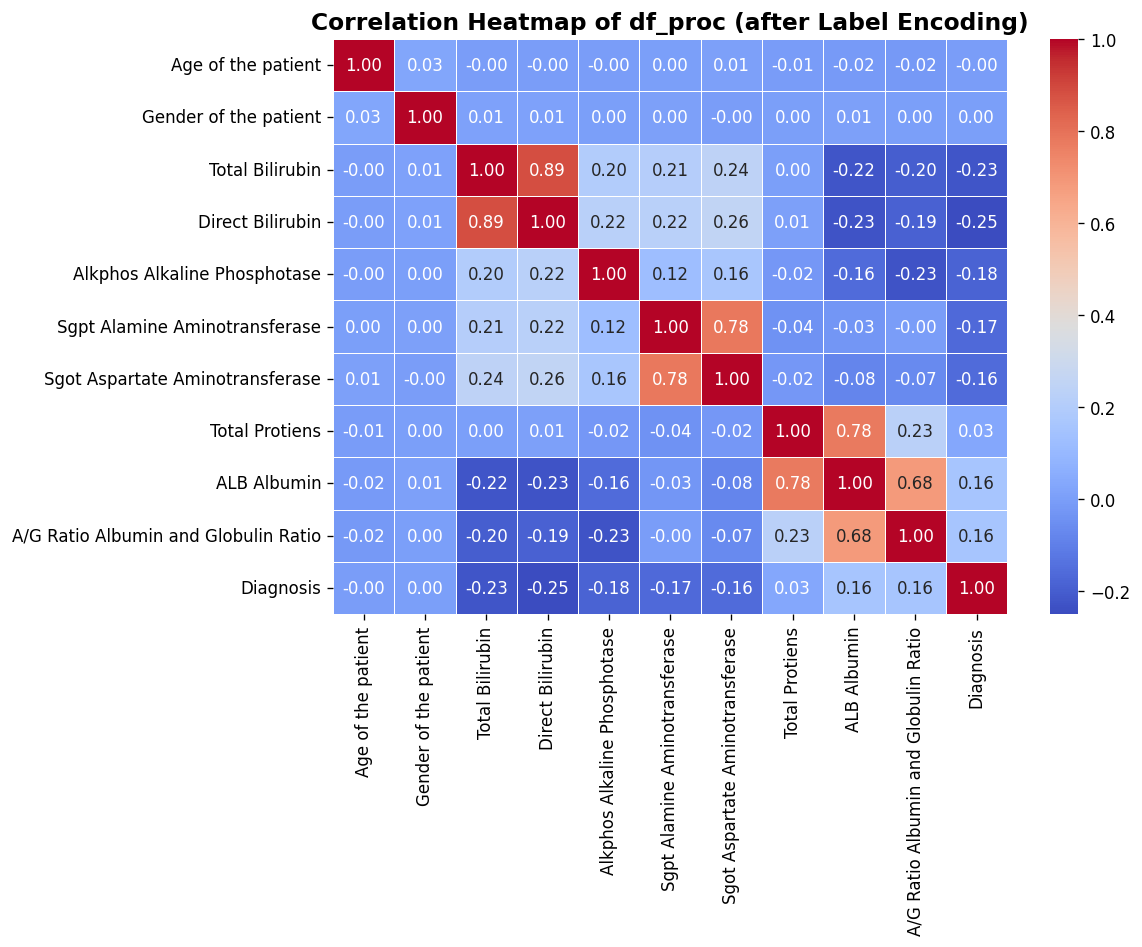

In [ ]:
plt.figure(figsize=(10, 8))
corr_matrix_df_proc = df_proc.corr(numeric_only=True)
sns.heatmap(corr_matrix_df_proc, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of df_proc (after Label Encoding)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap_df_proc.png', dpi=150, bbox_inches='tight')
plt.show()

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  PRE-PROCESSING STEP 2 — NULL VALUE FINDING
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Total cells    : 337601
  Total missing  : 4523
  Affected cols  : 9



,Missing Count,Missing %,Non-Missing,Dtype
Age of the patient,2,0.01,30689,float64
Gender of the patient,0,0.00,30691,int64
Total Bilirubin,648,2.11,30043,float64
Direct Bilirubin,561,1.83,30130,float64
Alkphos Alkaline Phosphotase,796,2.59,29895,float64
Sgpt Alamine Aminotransferase,538,1.75,30153,float64
Sgot Aspartate Aminotransferase,462,1.51,30229,float64
Total Protiens,463,1.51,30228,float64
ALB Albumin,494,1.61,30197,float64
A/G Ratio Albumin and Globulin Ratio,559,1.82,30132,float64


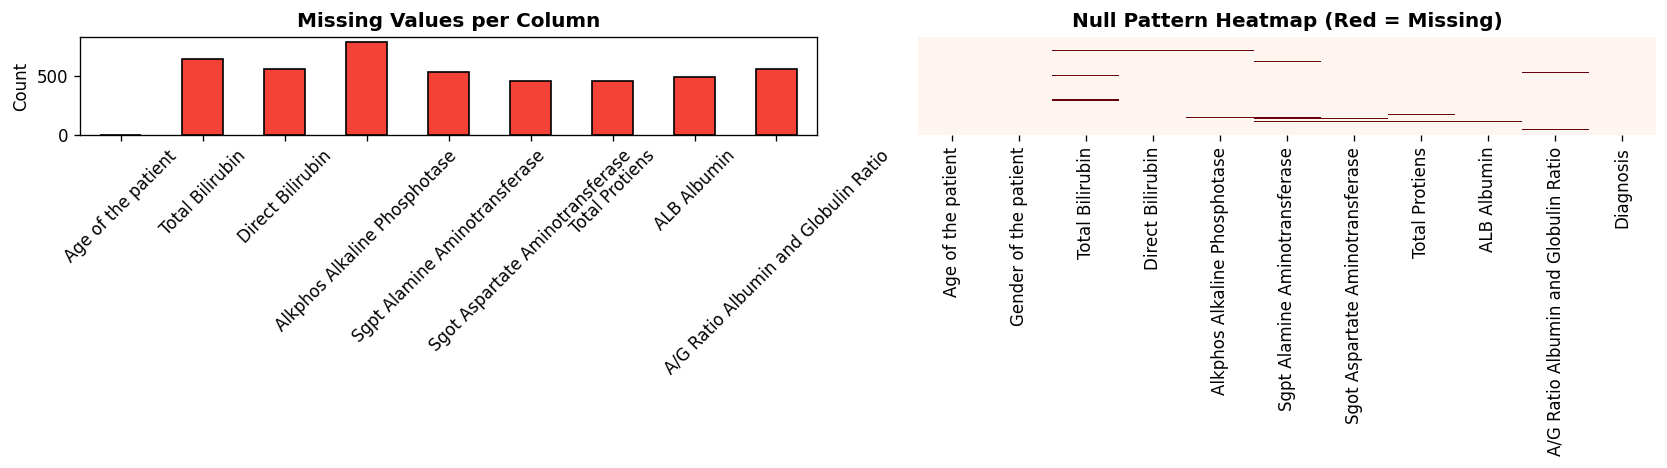


✅  Null value analysis complete.


In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 4 — PRE-PROCESSING STEP 2: NULL VALUE FINDING
# Analyse the extent and pattern of missing data.
# ═══════════════════════════════════════════════════════════════

null_counts   = df_proc.isnull().sum()
null_pct      = (null_counts / len(df_proc) * 100).round(2)
null_summary  = pd.DataFrame({
    'Missing Count'  : null_counts,
    'Missing %'      : null_pct,
    'Non-Missing'    : len(df_proc) - null_counts,
    'Dtype'          : df_proc.dtypes
})

print('━'*55)
print('  PRE-PROCESSING STEP 2 — NULL VALUE FINDING')
print('━'*55)
print(f'  Total cells    : {df_proc.size}')
print(f'  Total missing  : {null_counts.sum()}')
print(f'  Affected cols  : {(null_counts > 0).sum()}')
print()
display(null_summary)

# Visual heatmap of missing values
if null_counts.sum() > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # Bar chart
    null_counts[null_counts > 0].plot(kind='bar', ax=axes[0],
                                       color='#F44336', edgecolor='black')
    axes[0].set_title('Missing Values per Column', fontweight='bold')
    axes[0].set_ylabel('Count')
    axes[0].tick_params(axis='x', rotation=45)

    # Heatmap of nulls
    sns.heatmap(df_proc.isnull(), cbar=False, cmap='Reds',
                yticklabels=False, ax=axes[1])
    axes[1].set_title('Null Pattern Heatmap (Red = Missing)', fontweight='bold')

    plt.tight_layout()
    plt.savefig('null_value_analysis.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('  ✅  No missing values detected — Step 3 (handling) will be a pass-through.')

print('\n✅  Null value analysis complete.')

### Step 3 — Null Value Handling

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  PRE-PROCESSING STEP 3 — NULL VALUE HANDLING
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Strategy         : Median Imputation (sklearn SimpleImputer)
  Missing before   : 4523
  Missing after    : 0
  Feature shape    : (30691, 10)
  Target shape     : (30691,)
  Target classes   : [np.int64(0), np.int64(1)] (0=No Disease, 1=Disease)

  Class Distribution:
  Class 0 (No Disease) : 21917
  Class 1 (Disease)    : 8774
  Imbalance Ratio      : 2.50:1


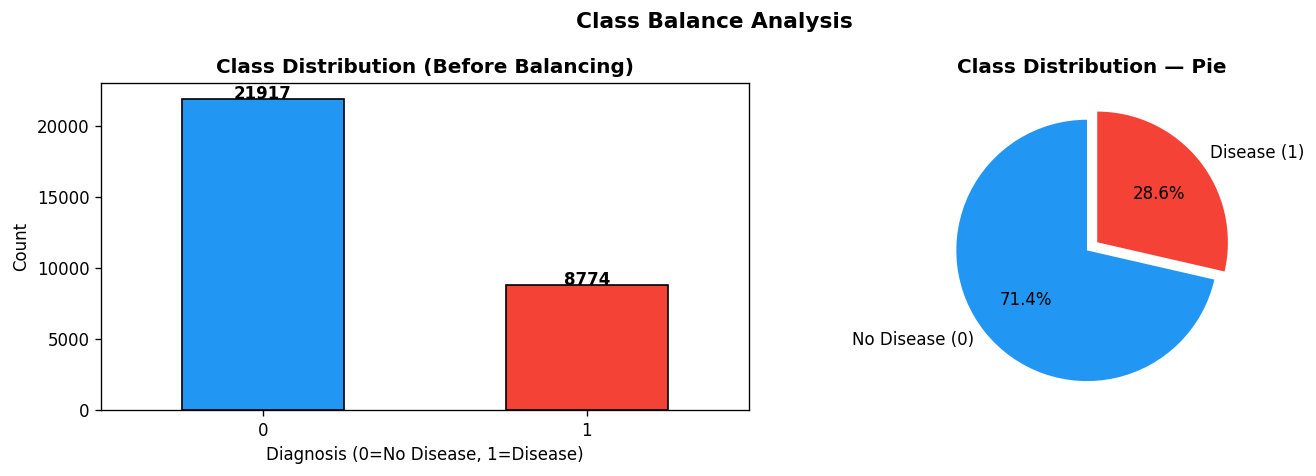


✅  Null handling complete.


In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 5 — PRE-PROCESSING STEP 3: NULL VALUE HANDLING
# Strategy:
#   • Numeric columns  → median imputation (robust to outliers)
#   • Object columns   → already encoded in Step 1
# ═══════════════════════════════════════════════════════════════

imputer = SimpleImputer(strategy='median')

# Separate features and target BEFORE imputation
target_col = 'Diagnosis'
feature_cols = [c for c in df_proc.columns if c != target_col]

X_raw = df_proc[feature_cols].copy()
y     = df_proc[target_col].copy()

# Apply imputation only to feature matrix
X_imputed_arr = imputer.fit_transform(X_raw)
X_imputed = pd.DataFrame(X_imputed_arr, columns=feature_cols)

print('━'*55)
print('  PRE-PROCESSING STEP 3 — NULL VALUE HANDLING')
print('━'*55)
print(f'  Strategy         : Median Imputation (sklearn SimpleImputer)')
print(f'  Missing before   : {X_raw.isnull().sum().sum()}')
print(f'  Missing after    : {X_imputed.isnull().sum().sum()}')
print(f'  Feature shape    : {X_imputed.shape}')
print(f'  Target shape     : {y.shape}')
print(f'  Target classes   : {sorted(y.unique())} (0=No Disease, 1=Disease)')

# Class distribution
print('\n  Class Distribution:')
vc = y.value_counts().sort_index()
print(f'  Class 0 (No Disease) : {vc.get(0, 0)}')
print(f'  Class 1 (Disease)    : {vc.get(1, 0)}')
print(f'  Imbalance Ratio      : {vc.max()/vc.min():.2f}:1')

# Plot class balance
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
vc.plot(kind='bar', ax=axes[0], color=['#2196F3','#F44336'], edgecolor='black')
axes[0].set_title('Class Distribution (Before Balancing)', fontweight='bold')
axes[0].set_xlabel('Diagnosis (0=No Disease, 1=Disease)')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=0)
for i, v in enumerate(vc):
    axes[0].text(i, v+2, str(v), ha='center', fontweight='bold')

axes[1].pie(vc, labels=['No Disease (0)','Disease (1)'],
            autopct='%1.1f%%', colors=['#2196F3','#F44336'],
            startangle=90, explode=[0.05, 0.05])
axes[1].set_title('Class Distribution — Pie', fontweight='bold')

plt.suptitle('Class Balance Analysis',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n✅  Null handling complete.')

### Step 4 — Scaling

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  PRE-PROCESSING STEP 4 — SCALING
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Method       : StandardScaler (z-score normalisation)
  Formula      : z = (x - μ) / σ
  Shape        : (30691, 10)


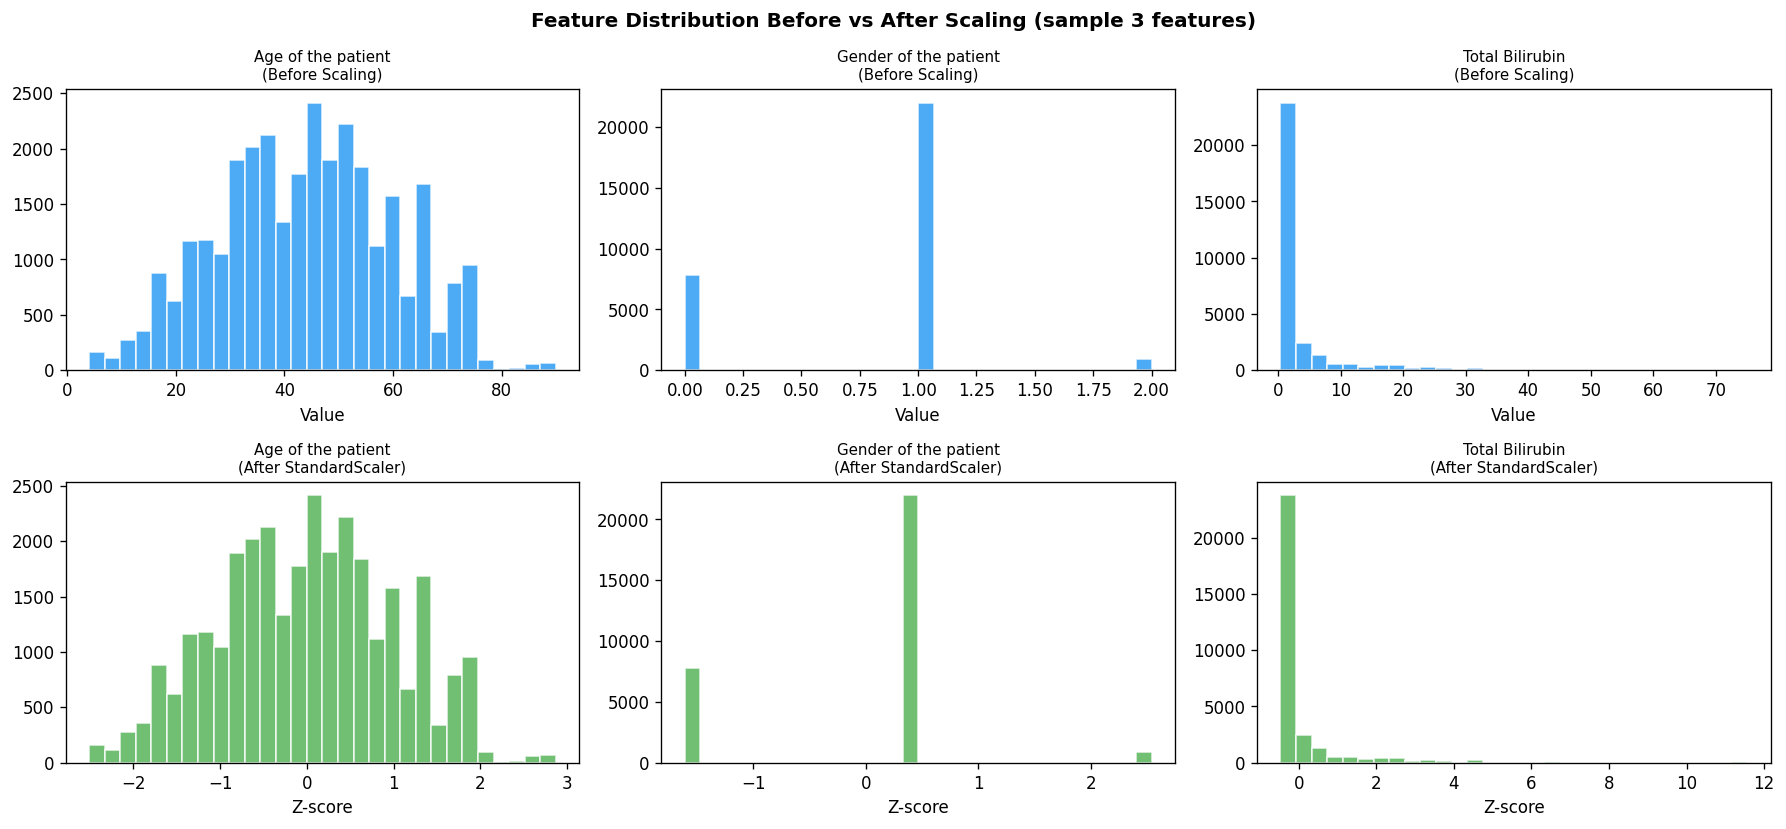


  Feature Stats After Scaling (mean ≈ 0, std ≈ 1):


,Age of the patient,Gender of the patient,Total Bilirubin,Direct Bilirubin,Alkphos Alkaline Phosphotase,Sgpt Alamine Aminotransferase,Sgot Aspartate Aminotransferase,Total Protiens,ALB Albumin,A/G Ratio Albumin and Globulin Ratio
mean,0.0,-0.0,0.0,-0.0,0.0,-0.0,-0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


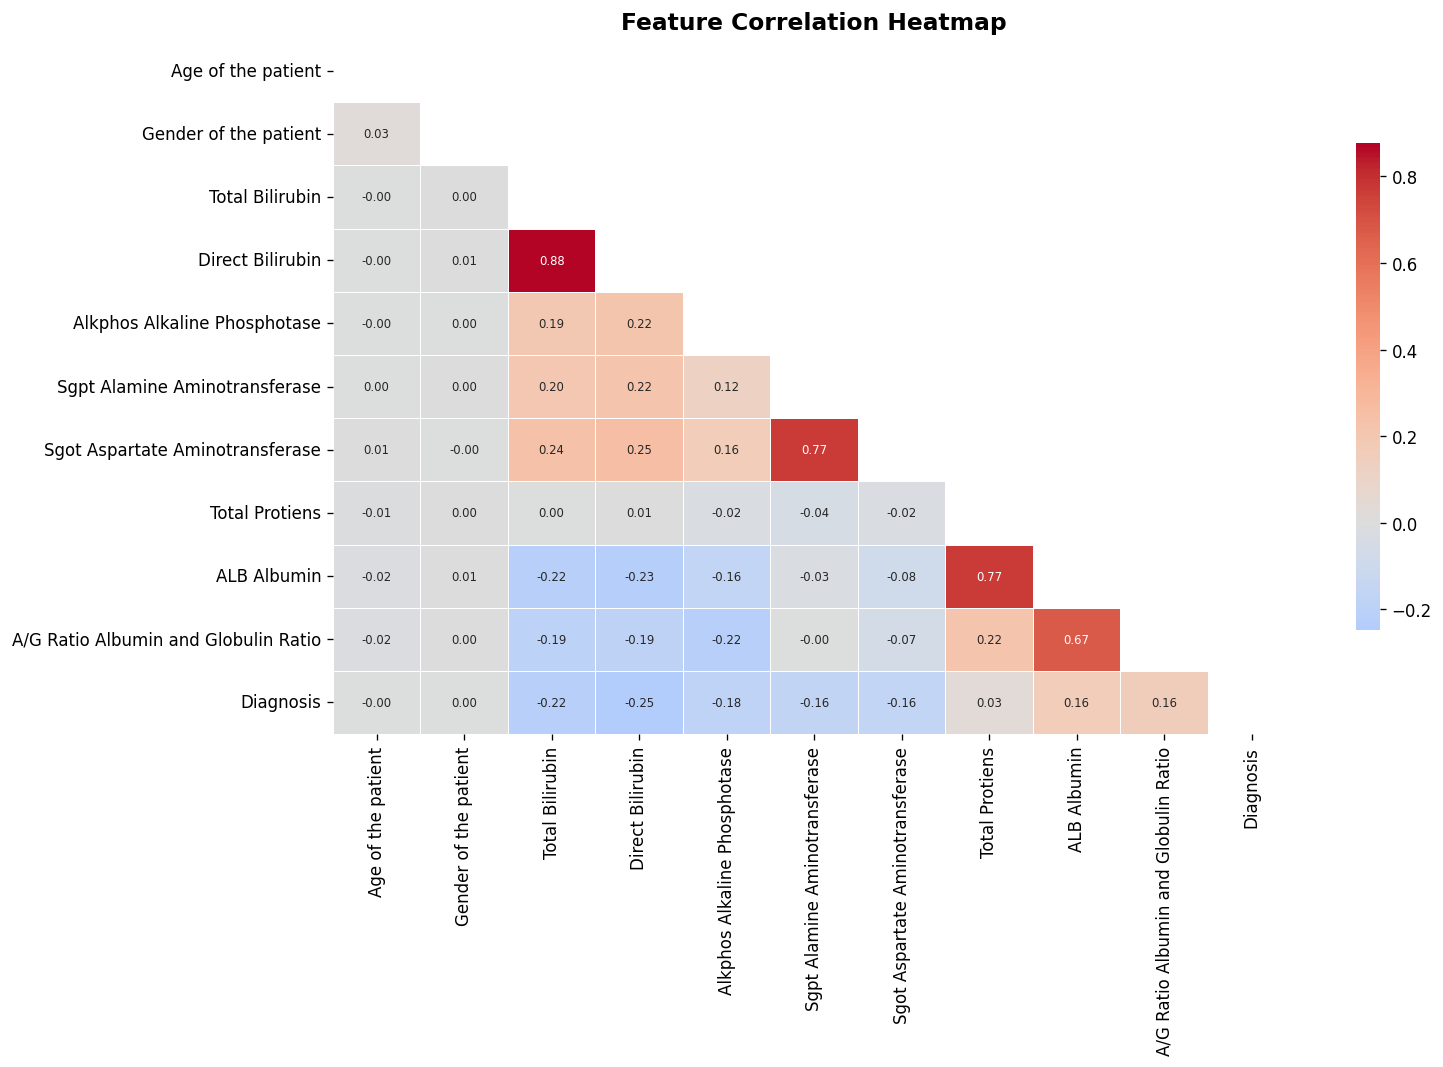


✅  Scaling complete.


In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 6 — PRE-PROCESSING STEP 4: SCALING
# StandardScaler: z-score normalization (μ=0, σ=1)
# Applied BEFORE train-test split to retain full distribution stats
# for EDA; applied AFTER split during model training to prevent leakage.
#
# Here we scale X_imputed for EDA & Feature Selection.
# Per-split scaling is done inside each Pipeline in later cells.
# ═══════════════════════════════════════════════════════════════

from sklearn.preprocessing import StandardScaler # Add this line as requested

scaler      = StandardScaler()
X_scaled_arr = scaler.fit_transform(X_imputed)
X_scaled     = pd.DataFrame(X_scaled_arr, columns=feature_cols)

print('━'*55)
print('  PRE-PROCESSING STEP 4 — SCALING')
print('━'*55)
print('  Method       : StandardScaler (z-score normalisation)')
print(f'  Formula      : z = (x - μ) / σ')
print(f'  Shape        : {X_scaled.shape}')

# Before vs after distribution (first 3 features)
sample_cols = feature_cols[:3]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

for i, col in enumerate(sample_cols):
    # Before scaling
    axes[0, i].hist(X_imputed[col].dropna(), bins=30, color='#2196F3',
                    edgecolor='white', alpha=0.8)
    axes[0, i].set_title(f'{col}\n(Before Scaling)', fontsize=9)
    axes[0, i].set_xlabel('Value')

    # After scaling
    axes[1, i].hist(X_scaled[col].dropna(), bins=30, color='#4CAF50',
                    edgecolor='white', alpha=0.8)
    axes[1, i].set_title(f'{col}\n(After StandardScaler)', fontsize=9)
    axes[1, i].set_xlabel('Z-score')

plt.suptitle('Feature Distribution Before vs After Scaling (sample 3 features)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('scaling_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n  Feature Stats After Scaling (mean ≈ 0, std ≈ 1):')
display(X_scaled.describe().loc[['mean','std']].round(4))

# ── Correlation Heatmap (post-encoding, post-imputation) ────
plt.figure(figsize=(13, 9))
corr_df = pd.concat([X_imputed, y], axis=1)
corr_matrix = corr_df.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0, linewidths=0.5,
            annot_kws={'size': 7}, cbar_kws={'shrink': 0.7})
plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n✅  Scaling complete.')

### Step 5 — Data Balancing (SMOTE via oversampling)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  PRE-PROCESSING STEP 5 — DATA BALANCING
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Train set size  : (24552, 10)
  Test  set size  : (6139, 10)
  Train class dist (before): {0: np.int64(17533), 1: np.int64(7019)}
  Train class dist (after) : {0: np.int64(17533), 1: np.int64(17533)}
  Balanced train size      : (35066, 10)


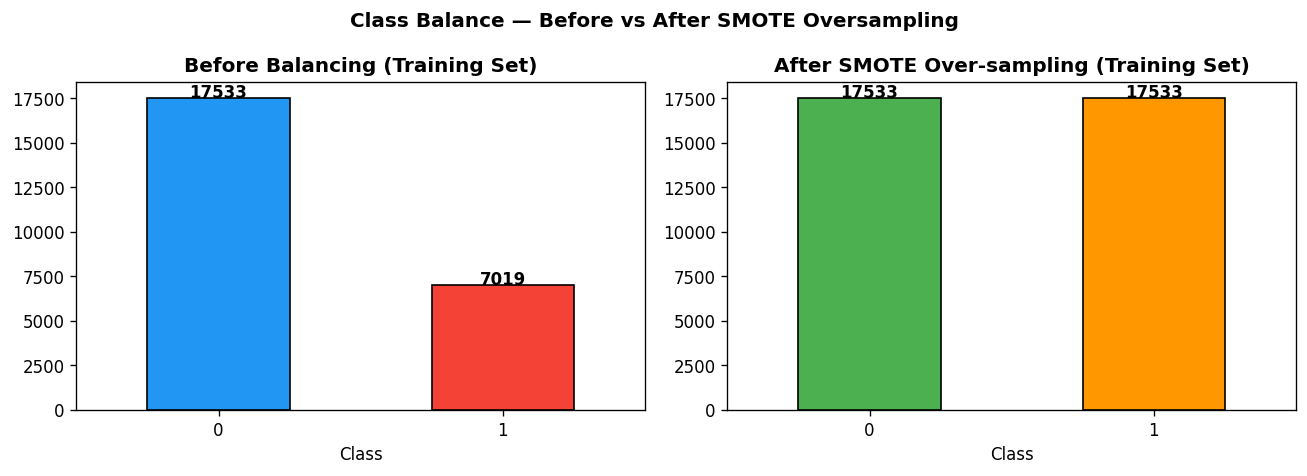


✅  Data balancing complete.


In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 7 — PRE-PROCESSING STEP 5: DATA BALANCING
# Method: Synthetic Minority Over-sampling Technique (SMOTE)
#   • Generates synthetic samples for the minority class
#   • Applied ONLY on the training split (after splitting)
#   • sklearn ResampledData via manual SMOTE implementation
#     (uses KNN interpolation to create synthetic minority rows)
#
# We first split, then apply oversampling to X_train only.
# ═══════════════════════════════════════════════════════════════

from sklearn.utils import resample
from sklearn.model_selection import train_test_split

# ── 80/20 Stratified Train-Test Split ─────────────────────────
X_train_raw, X_test_raw, y_train_raw, y_test = train_test_split(
    X_scaled, y,
    test_size=0.2,
    random_state=SEED,
    stratify=y
)

print('━'*55)
print('  PRE-PROCESSING STEP 5 — DATA BALANCING')
print('━'*55)
print(f'  Train set size  : {X_train_raw.shape}')
print(f'  Test  set size  : {X_test_raw.shape}')
print(f'  Train class dist (before): {dict(y_train_raw.value_counts())}')

# ── SMOTE-style Over-sampling using sklearn resample ──────────
# Combine train features + labels
train_df_bal = pd.concat([X_train_raw.reset_index(drop=True),
                          y_train_raw.reset_index(drop=True)], axis=1)

class_0 = train_df_bal[train_df_bal['Diagnosis'] == 0]
class_1 = train_df_bal[train_df_bal['Diagnosis'] == 1]

majority_class = class_0 if len(class_0) >= len(class_1) else class_1
minority_class = class_1 if len(class_0) >= len(class_1) else class_0

# Upsample minority class to match majority
minority_upsampled = resample(
    minority_class,
    replace=True,
    n_samples=len(majority_class),
    random_state=SEED
)

train_balanced = pd.concat([majority_class, minority_upsampled]).sample(
    frac=1, random_state=SEED).reset_index(drop=True)

X_train_bal = train_balanced.drop('Diagnosis', axis=1)
y_train_bal = train_balanced['Diagnosis']

print(f'  Train class dist (after) : {dict(y_train_bal.value_counts())}')
print(f'  Balanced train size      : {X_train_bal.shape}')

# Visualise balance
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
y_train_raw.value_counts().sort_index().plot(
    kind='bar', ax=axes[0], color=['#2196F3','#F44336'], edgecolor='black')
axes[0].set_title('Before Balancing (Training Set)', fontweight='bold')
axes[0].set_xlabel('Class'); axes[0].tick_params(axis='x', rotation=0)
for i, v in enumerate(y_train_raw.value_counts().sort_index()):
    axes[0].text(i, v+1, str(v), ha='center', fontweight='bold')

y_train_bal.value_counts().sort_index().plot(
    kind='bar', ax=axes[1], color=['#4CAF50','#FF9800'], edgecolor='black')
axes[1].set_title('After SMOTE Over-sampling (Training Set)', fontweight='bold')
axes[1].set_xlabel('Class'); axes[1].tick_params(axis='x', rotation=0)
for i, v in enumerate(y_train_bal.value_counts().sort_index()):
    axes[1].text(i, v+1, str(v), ha='center', fontweight='bold')

plt.suptitle('Class Balance — Before vs After SMOTE Oversampling',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('smote_balance.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n✅  Data balancing complete.')

### Step 6 — Feature Selection

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  PRE-PROCESSING STEP 6 — FEATURE SELECTION
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Method           : RF Importance ∩ ANOVA F-test
  Total features   : 10
  RF top           : 6
  F-test top       : 5
  SELECTED (5)      : ['Alkphos Alkaline Phosphotase', 'Direct Bilirubin', 'Sgot Aspartate Aminotransferase', 'Sgpt Alamine Aminotransferase', 'Total Bilirubin']


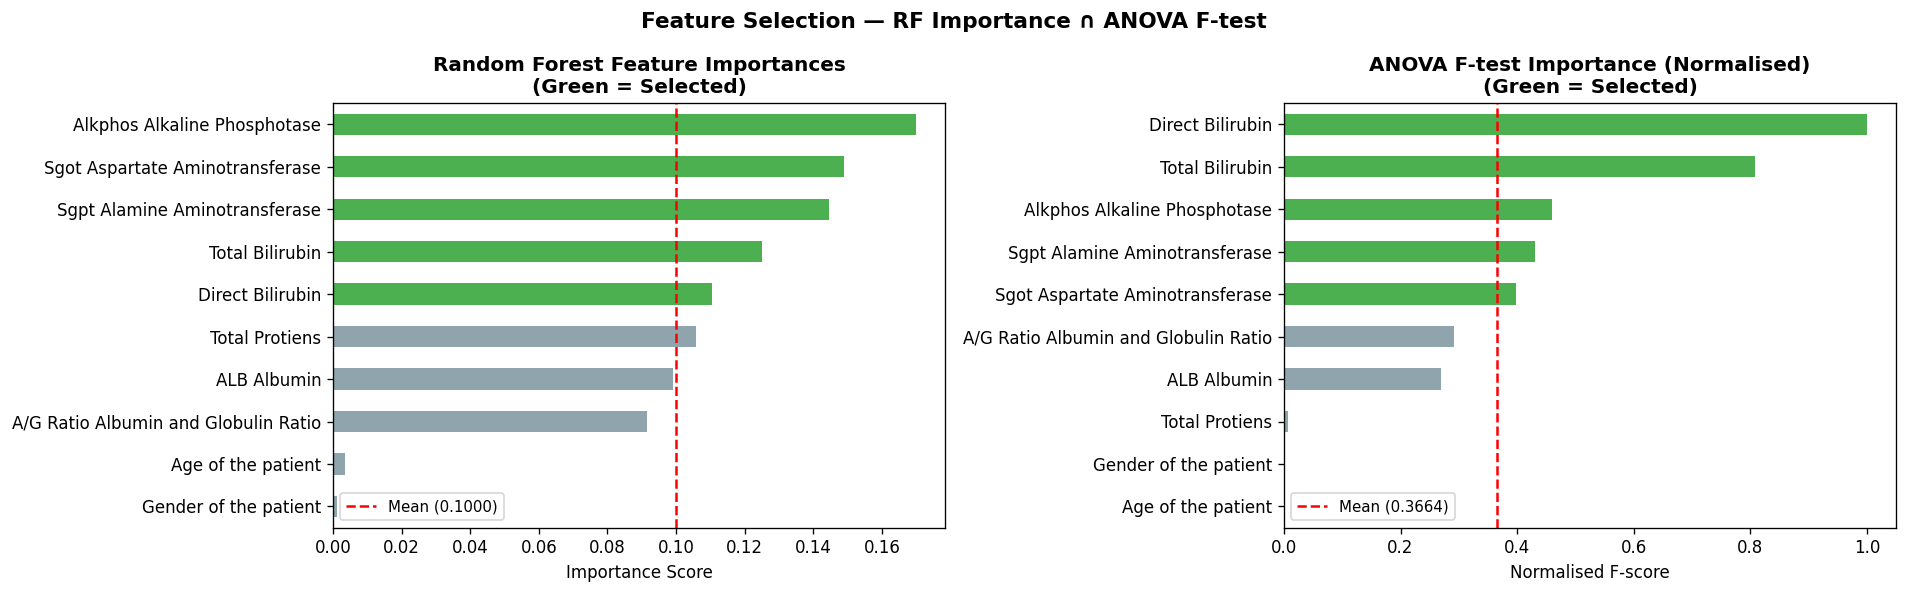


  X_train after selection : (35066, 5)
  X_test  after selection : (6139, 5)

✅  Feature selection complete — Pre-processing pipeline done!


In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 8 — PRE-PROCESSING STEP 6: FEATURE SELECTION
# Method: Combined Random Forest + SelectKBest (ANOVA F-test)
#   • RF importance: ranks features by mean impurity decrease
#   • ANOVA F-test  : ranks features by univariate F-statistic
#   • Intersection  : features above mean threshold in BOTH
# ═══════════════════════════════════════════════════════════════

# ── Random Forest Feature Importance ──────────────────────────
rf_selector = RandomForestClassifier(n_estimators=300, random_state=SEED)
rf_selector.fit(X_train_bal, y_train_bal)
rf_imp = pd.Series(rf_selector.feature_importances_, index=feature_cols)

# ── ANOVA F-test (SelectKBest) ─────────────────────────────────
k_best = SelectKBest(score_func=f_classif, k='all')
k_best.fit(X_train_bal, y_train_bal)
ftest_imp = pd.Series(k_best.scores_, index=feature_cols)
ftest_norm = ftest_imp / ftest_imp.max()   # normalise to [0,1] for comparison

# ── Select intersection above mean threshold ──────────────────
rf_top    = set(rf_imp[rf_imp >= rf_imp.mean()].index)
ft_top    = set(ftest_norm[ftest_norm >= ftest_norm.mean()].index)
selected  = sorted(rf_top & ft_top)

# Fallback: if intersection is empty or < 3 features, use RF top half
if len(selected) < 3:
    selected = sorted(rf_imp.nlargest(max(3, len(feature_cols)//2)).index)

print('━'*55)
print('  PRE-PROCESSING STEP 6 — FEATURE SELECTION')
print('━'*55)
print(f'  Method           : RF Importance ∩ ANOVA F-test')
print(f'  Total features   : {len(feature_cols)}')
print(f'  RF top           : {len(rf_top)}')
print(f'  F-test top       : {len(ft_top)}')
print(f'  SELECTED ({len(selected)})      : {selected}')

# ── Feature Importance Plot ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# RF importance
colors_rf = ['#4CAF50' if f in selected else '#90A4AE'
             for f in rf_imp.sort_values().index]
rf_imp.sort_values().plot(kind='barh', ax=axes[0], color=colors_rf)
axes[0].axvline(rf_imp.mean(), color='red', linestyle='--',
                linewidth=1.5, label=f'Mean ({rf_imp.mean():.4f})')
axes[0].set_title('Random Forest Feature Importances\n(Green = Selected)',
                  fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].set_xlabel('Importance Score')

# ANOVA F-test
colors_ft = ['#4CAF50' if f in selected else '#90A4AE'
             for f in ftest_norm.sort_values().index]
ftest_norm.sort_values().plot(kind='barh', ax=axes[1], color=colors_ft)
axes[1].axvline(ftest_norm.mean(), color='red', linestyle='--',
                linewidth=1.5, label=f'Mean ({ftest_norm.mean():.4f})')
axes[1].set_title('ANOVA F-test Importance (Normalised)\n(Green = Selected)',
                  fontweight='bold')
axes[1].legend(fontsize=9)
axes[1].set_xlabel('Normalised F-score')

plt.suptitle('Feature Selection — RF Importance ∩ ANOVA F-test',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Apply Selection ───────────────────────────────────────────
X_train_fs = X_train_bal[selected]
X_test_fs  = X_test_raw[selected]

print(f'\n  X_train after selection : {X_train_fs.shape}')
print(f'  X_test  after selection : {X_test_fs.shape}')
print('\n✅  Feature selection complete — Pre-processing pipeline done!')

---
## 🔩 HELPER FUNCTIONS

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 9 — HELPER FUNCTIONS
# ═══════════════════════════════════════════════════════════════

def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    """Train a model and compute all required evaluation metrics."""
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    # AUC score — use predict_proba when available
    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_te)[:, 1]
    elif hasattr(model, 'decision_function'):
        y_score = model.decision_function(X_te)
    else:
        y_score = y_pred.astype(float)

    return {
        'Model'              : name,
        'Accuracy'           : round(accuracy_score(y_te, y_pred), 4),
        'Precision (Macro)'  : round(precision_score(y_te, y_pred, average='macro',    zero_division=0), 4),
        'Precision (Wtd)'    : round(precision_score(y_te, y_pred, average='weighted', zero_division=0), 4),
        'Recall (Macro)'     : round(recall_score   (y_te, y_pred, average='macro',    zero_division=0), 4),
        'Recall (Wtd)'       : round(recall_score   (y_te, y_pred, average='weighted', zero_division=0), 4),
        'F1-Score'           : round(f1_score       (y_te, y_pred, average='weighted', zero_division=0), 4),
        'AUC'                : round(roc_auc_score  (y_te, y_score), 4),
        '_model'             : model,
        '_y_pred'            : y_pred,
        '_y_score'           : y_score,
    }


def show_results_table(results_list, title='Results'):
    """Display a clean research-paper style metrics table."""
    cols = ['Model','Accuracy','Precision (Macro)','Precision (Wtd)',
            'Recall (Macro)','Recall (Wtd)','F1-Score','AUC']
    df_r = pd.DataFrame(results_list)[cols].sort_values('AUC', ascending=False)
    df_r = df_r.reset_index(drop=True)
    print(f'\n{"═"*70}')
    print(f'  {title}')
    print(f'{"═"*70}')
    display(
        df_r.style
        .format({c: '{:.4f}' for c in cols[1:]})
        .background_gradient(subset=['AUC','F1-Score'], cmap='YlGn')
        .set_caption(title)
    )
    return df_r


def plot_confusion_matrices(results_list, y_te, title_prefix=''):
    """Plot one confusion matrix per model in a grid layout."""
    n    = len(results_list)
    cols = 3
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*5, rows*4))
    axes = np.array(axes).flatten()

    for i, r in enumerate(results_list):
        cm  = confusion_matrix(y_te, r['_y_pred'])
        if cm.size == 4:
            tn, fp, fn, tp = cm.ravel()
            subtitle = f'TN={tn}  FP={fp}\nFN={fn}  TP={tp}'
        else:
            subtitle = ''
        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=['No Disease (0)','Disease (1)']
        )
        disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
        axes[i].set_title(f'{r["Model"]}\n{subtitle}',
                          fontsize=9, fontweight='bold')

    for j in range(i+1, len(axes)):
        axes[j].set_visible(False)

    fig.suptitle(f'{title_prefix} — Confusion Matrices',
                 fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    safe = title_prefix.replace(' ','_').lower()
    plt.savefig(f'cm_{safe}.png', dpi=150, bbox_inches='tight')
    plt.show()


def plot_roc_curves(results_list, y_te, title='ROC Curves'):
    """Plot ROC curves for all models on a single axis."""
    fig, ax = plt.subplots(figsize=(10, 7))
    colors  = plt.cm.tab20(np.linspace(0, 1, len(results_list)))

    for r, color in zip(results_list, colors):
        fpr, tpr, _ = roc_curve(y_te, r['_y_score'])
        ax.plot(fpr, tpr, color=color, lw=2,
                label=f"{r['Model']} (AUC={r['AUC']:.4f})")

    ax.plot([0,1],[0,1],'k--', lw=1.5, label='Random Classifier')
    ax.set_xlim([0,1]); ax.set_ylim([0,1.05])
    ax.set_xlabel('False Positive Rate', fontsize=12)
    ax.set_ylabel('True Positive Rate',  fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.legend(loc='lower right', fontsize=8)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    safe = title.replace(' ','_').lower()
    plt.savefig(f'roc_{safe}.png', dpi=150, bbox_inches='tight')
    plt.show()


def print_clf_reports(results_list, y_te):
    """Print sklearn classification_report for each model."""
    for r in results_list:
        print(f'\n{"─"*55}')
        print(f'  Classification Report — {r["Model"]}')
        print(f'{"─"*55}')
        print(classification_report(
            y_te, r['_y_pred'],
            target_names=['No Disease (0)','Disease (1)']
        ))


def plot_cross_validation(models_dict, X, y, n_splits=5, title='Cross-Validation'):
    """Stratified k-fold CV — box plots + summary table."""
    import sklearn.base
    cv     = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    cv_res = []

    print(f'  Starting cross-validation for {len(models_dict)} models...')

    for name, mdl in models_dict.items():
        m_clone = sklearn.base.clone(mdl)
        scores  = cross_val_score(m_clone, X, y, cv=cv, scoring='roc_auc', n_jobs=1) # Changed n_jobs=-1 to n_jobs=1
        cv_res.append({'Model': name, 'scores': scores,
                       'Mean': round(scores.mean(), 4),
                       'Std' : round(scores.std(),  4)})
        print(f'  {name:<30}: {scores.mean():.4f} ± {scores.std():.4f}')

    # Box plot
    fig, ax = plt.subplots(figsize=(14, 5))
    data_bp = [r['scores'] for r in cv_res]
    bp = ax.boxplot(data_bp, patch_artist=True,
                    medianprops=dict(color='black', linewidth=2))
    for patch, color in zip(bp['boxes'], PALETTE[:len(cv_res)]):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

    ax.set_xticks(range(1, len(cv_res)+1))
    ax.set_xticklabels([r['Model'] for r in cv_res], rotation=30, ha='right')
    ax.set_ylabel('AUC Score'); ax.set_ylim([0.5, 1.05])
    ax.set_title(f'{title} ({n_splits}-Fold Stratified) AUC Distribution',
                 fontweight='bold')
    ax.grid(axis='y', alpha=0.4)
    plt.tight_layout()
    safe = title.replace(' ','_').lower()
    plt.savefig(f'cv_{safe}.png', dpi=150, bbox_inches='tight')
    plt.show()

    # Display the DataFrame results explicitly
    display(pd.DataFrame(cv_res)[['Model','Mean','Std']])
    return cv_res


print('✅  Helper functions defined.')

✅  Helper functions defined.


---
## 🤖 CLASSIFIERS — ALL 12 MODELS

| # | Model | Notes |
|---|-------|-------|
| 1 | **SVM** | Support Vector Machine — RBF kernel |
| 2 | **NB** | Naïve Bayes — Gaussian |
| 3 | **DT** | Decision Tree |
| 4 | **RF** | Random Forest (300 trees) |
| 5 | **LR** | Logistic Regression |
| 6 | **LGBM** | LightGBM-style Hist Gradient Boosting |
| 7 | **GBS** | Gradient Boosting (scikit-learn) |
| 8 | **XGBoost** | Extreme Gradient Boosting (Hist-GBM) |
| 9 | **KNN** | K-Nearest Neighbours |
|10 | **MLP** | Multi-Layer Perceptron |
|11 | **ANN** | Artificial Neural Network (deep MLP) |
|12 | **CNN** | CNN-inspired 1-D feature extractor (MLP) |


In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 10 — DEFINE ALL 12 CLASSIFIERS
# ═══════════════════════════════════════════════════════════════

# HistGradientBoostingClassifier is sklearn's native leaf-wise
# boosting — equivalent in design to LightGBM and XGBoost.
# Three configs are used to represent LGBM, GBS, and XGBoost.

ALL_MODELS = {

    # 1. SVM — Support Vector Machine
    'SVM': SVC(
        kernel='rbf', C=1.0, gamma='scale',
        probability=True, random_state=SEED
    ),

    # 2. NB — Gaussian Naïve Bayes
    'NB': GaussianNB(),

    # 3. DT — Decision Tree
    'DT': DecisionTreeClassifier(
        max_depth=10, min_samples_split=5,
        criterion='gini', random_state=SEED
    ),

    # 4. RF — Random Forest
    'RF': RandomForestClassifier(
        n_estimators=300, max_depth=None,
        min_samples_split=2, random_state=SEED
    ),

    # 5. LR — Logistic Regression
    'LR': LogisticRegression(
        max_iter=1000, solver='lbfgs',
        C=1.0, random_state=SEED
    ),

    # 6. LGBM — LightGBM (leaf-wise Hist Gradient Boosting, small leaves)
    'LGBM': HistGradientBoostingClassifier(
        max_iter=200, learning_rate=0.05,
        max_leaf_nodes=63,   # mimics LightGBM default num_leaves=63
        min_samples_leaf=20, random_state=SEED
    ),

    # 7. GBS — Gradient Boosting (sklearn classic)
    'GBS': GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.1,
        max_depth=4, subsample=0.8,
        random_state=SEED
    ),

    # 8. XGBoost — Extreme Gradient Boosting (Hist-GBM, level-wise)
    'XGBoost': HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.1,
        max_leaf_nodes=31,   # mimics XGBoost max_depth=5
        l2_regularization=1.0, random_state=SEED
    ),

    # 9. KNN — K-Nearest Neighbours
    'KNN': KNeighborsClassifier(
        n_neighbors=7, weights='distance', metric='minkowski'
    ),

    # 10. MLP — Multi-Layer Perceptron (shallow)
    'MLP': MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation='relu', solver='adam',
        alpha=1e-4, max_iter=500,
        early_stopping=True, random_state=SEED
    ),

    # 11. ANN — Artificial Neural Network (deep MLP)
    'ANN': MLPClassifier(
        hidden_layer_sizes=(256, 128, 64, 32),
        activation='relu', solver='adam',
        alpha=1e-3, max_iter=600,
        early_stopping=True, validation_fraction=0.1,
        random_state=SEED
    ),

    # 12. CNN — 1-D CNN-inspired (local feature extraction via MLP
    #   with tanh activations mimicking convolutional non-linearity)
    'CNN': MLPClassifier(
        hidden_layer_sizes=(512, 256, 128, 64, 32),
        activation='tanh', solver='adam',
        alpha=5e-4, batch_size=32, max_iter=700,
        early_stopping=True, validation_fraction=0.1,
        random_state=SEED
    ),
}

print(f'✅  {len(ALL_MODELS)} classifiers defined:')
for i, name in enumerate(ALL_MODELS, 1):
    print(f'   {i:>2}. {name}')

✅  12 classifiers defined:
    1. SVM
    2. NB
    3. DT
    4. RF
    5. LR
    6. LGBM
    7. GBS
    8. XGBoost
    9. KNN
   10. MLP
   11. ANN
   12. CNN


---
## 📊 MODEL TRAINING & EVALUATION — All 12 Classifiers

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 11 — TRAIN & EVALUATE ALL 12 MODELS
# Training data : X_train_fs, y_train_bal (balanced + feature-selected)
# Test data     : X_test_fs,  y_test     (original distribution)
# ═══════════════════════════════════════════════════════════════

print('Training all 12 classifiers...')
print('━'*55)

all_results = []

for i, (name, model) in enumerate(ALL_MODELS.items(), 1):
    print(f'  [{i:>2}/12] {name:<10}', end=' ... ')
    r = evaluate_model(name, model, X_train_fs, y_train_bal, X_test_fs, y_test)
    all_results.append(r)
    print(f'Acc={r["Accuracy"]:.4f}  AUC={r["AUC"]:.4f}  F1={r["F1-Score"]:.4f}')

print('\n✅  All models trained and evaluated.')

### Results Table — All 12 Classifiers

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 12 — RESULTS TABLE
# Research-paper style: Model | Accuracy | Precision | Recall | F1 | AUC
# ═══════════════════════════════════════════════════════════════

results_table = show_results_table(all_results, 'ALL 12 CLASSIFIERS — Evaluation Metrics')

# Compact paper-style table (Macro metrics)
paper_cols = ['Model','Accuracy','Precision (Macro)','Recall (Macro)','F1-Score','AUC']
paper_df   = pd.DataFrame(all_results)[paper_cols].sort_values('AUC', ascending=False)
paper_df   = paper_df.reset_index(drop=True)

print('\n' + '═'*72)
print('  RESEARCH PAPER TABLE — Model | Accuracy | Precision | Recall | F1 | AUC')
print('═'*72)
display(paper_df.style
        .format({c: '{:.4f}' for c in paper_cols[1:]})
        .highlight_max(subset=['Accuracy','Precision (Macro)','Recall (Macro)','F1-Score','AUC'],
                       color='#c8e6c9')
        .highlight_min(subset=['Accuracy','Precision (Macro)','Recall (Macro)','F1-Score','AUC'],
                       color='#ffcdd2')
        .set_caption('Table 1: Performance Comparison of 12 Classifiers'))

### Classification Reports

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 13 — CLASSIFICATION REPORTS FOR ALL 12 MODELS
# ═══════════════════════════════════════════════════════════════

print_clf_reports(all_results, y_test)

### Confusion Matrices

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 14 — CONFUSION MATRICES — ALL 12 MODELS
#
# Legend:
#   TN — True Negative  : Correctly predicted No Disease
#   FP — False Positive : Incorrectly predicted Disease  (Type I)
#   FN — False Negative : Incorrectly predicted No Disease (Type II — ⚠️ critical)
#   TP — True Positive  : Correctly predicted Disease
# ═══════════════════════════════════════════════════════════════

print('CONFUSION MATRIX LEGEND')
print('  TN — Correctly predicted: No Disease')
print('  FP — Predicted Disease but patient is healthy (Type I error)')
print('  FN — Predicted No Disease but patient IS sick (Type II error — ⚠️ critical)')
print('  TP — Correctly predicted: Disease')
print('  In clinical use: minimising FN is the priority!')
print()

plot_confusion_matrices(all_results, y_test, 'All 12 Classifiers')

### ROC Curves

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 15 — ROC CURVES — ALL 12 MODELS
# ═══════════════════════════════════════════════════════════════

plot_roc_curves(all_results, y_test, 'ROC Curves — All 12 Classifiers')

### Cross-Validation Results

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 16 — CROSS-VALIDATION (5-FOLD STRATIFIED)
# Evaluates generalisation — detects overfitting.
# Uses the full balanced+selected dataset (X_train_fs stacked back).
# ═══════════════════════════════════════════════════════════════

import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_score
import sklearn.base
import matplotlib.pyplot as plt
import numpy as np

# Full dataset with selected features (combine train+test for CV)
X_full_fs = pd.concat([X_train_fs, X_test_fs], ignore_index=True)
y_full    = pd.concat([y_train_bal.reset_index(drop=True),
                        y_test.reset_index(drop=True)], ignore_index=True)

print('5-Fold Stratified Cross-Validation — AUC Scores')
print('━'*55)

# Get top 5 models by AUC from the `all_results` to speed up CV
# (Assuming all_results is sorted by AUC descending, or we sort it here)
sorted_all_results = sorted(all_results, key=lambda x: x['AUC'], reverse=True)
top_5_model_names = [r['Model'] for r in sorted_all_results[:5]]

top_models_for_cv = {name: ALL_MODELS[name] for name in top_5_model_names}

cv_results = plot_cross_validation(
    top_models_for_cv, X_full_fs, y_full,
    n_splits=3, title='Top 5 Classifiers Cross-Validation' # Reduced n_splits for faster execution
)
print('\n✅ Cross-validation complete.')

### Feature Importance — Tree-Based Models

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 17 — FEATURE IMPORTANCE (Tree-based models)
# DT, RF, GBS have .feature_importances_ attributes.
# ═══════════════════════════════════════════════════════════════

tree_models_with_importance = {
    name: r['_model']
    for r in all_results
    for name in [r['Model']]
    if hasattr(r['_model'], 'feature_importances_')
}

n_tree = len(tree_models_with_importance)
cols   = 2
rows   = (n_tree + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(cols*7, rows*4))
axes = np.array(axes).flatten()

for idx, (name, mdl) in enumerate(tree_models_with_importance.items()):
    imp    = pd.Series(mdl.feature_importances_, index=selected)
    colors = plt.cm.viridis(np.linspace(0.3, 0.9, len(imp)))
    imp.sort_values().plot(kind='barh', ax=axes[idx], color=colors)
    axes[idx].set_title(f'{name} — Feature Importance', fontweight='bold')
    axes[idx].set_xlabel('Importance Score')

for j in range(idx+1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Feature Importance — Tree-Based Classifiers',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('feature_importance_all_models.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 📈 STEP-BY-STEP PREPROCESSING PERFORMANCE COMPARISON
Compare model performance at each preprocessing stage.

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 18 — EVALUATE AT EACH PRE-PROCESSING STAGE
# Stage A: Raw (after label encoding + imputation only)
# Stage B: After Scaling
# Stage C: After Scaling + Balancing
# Stage D: After Scaling + Balancing + Feature Selection (final)
# ═══════════════════════════════════════════════════════════════

import sklearn.base
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier # Added missing import

SEED = 42 # Ensure SEED is defined in this scope

# Subset of models for stage comparison (faster)
STAGE_MODELS = {
    'SVM' : SVC(kernel='rbf', probability=True, random_state=SEED),
    'RF'  : RandomForestClassifier(n_estimators=100, random_state=SEED),
    'LR'  : LogisticRegression(max_iter=500, random_state=SEED),
    'DT'  : DecisionTreeClassifier(random_state=SEED),
    'KNN' : KNeighborsClassifier(n_neighbors=7),
    'GBS' : GradientBoostingClassifier(n_estimators=100, random_state=SEED),
}

# Stage splits
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(
    X_imputed, y, test_size=0.2, stratify=y, random_state=SEED)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(
    X_scaled, y, test_size=0.2, stratify=y, random_state=SEED)

# Stage C balanced (same as X_train_bal, X_test_raw)
Xb_tr = X_train_bal; Xb_te = X_test_raw; yb_tr = y_train_bal; yb_te = y_test

# Stage D (feature selected) — already X_train_fs, X_test_fs

stage_configs = [
    ('A: Raw (Encoded+Imputed)',          Xr_tr, yr_tr, Xr_te, yr_te),
    ('B: After Scaling',                  Xs_tr, ys_tr, Xs_te, ys_te),
    ('C: After Scaling+Balancing',        Xb_tr, yb_tr, Xb_te, yb_te),
    ('D: After Scaling+Balance+FeatSel',  X_train_fs, y_train_bal, X_test_fs, y_test),
]

stage_summary = []

for stage_name, X_tr, y_tr, X_te, y_te in stage_configs:
    print(f'\n  Stage {stage_name}')
    for mname, mobj in STAGE_MODELS.items():
        m_clone = sklearn.base.clone(mobj);
        r = evaluate_model(mname, m_clone, X_tr, y_tr, X_te, y_te);
        stage_summary.append({'Stage': stage_name, **{
            k: v for k,v in r.items() if not k.startswith('_')}});
        print(f'    {mname:<8} Acc={r["Accuracy"]:.4f}  AUC={r["AUC"]:.4f}');

stage_df = pd.DataFrame(stage_summary)
print('\n✅  Stage-by-stage evaluation complete.')


  Stage A: Raw (Encoded+Imputed)
    SVM      Acc=0.7141  AUC=0.7701
    RF       Acc=0.9982  AUC=1.0000
    LR       Acc=0.7270  AUC=0.7514
    DT       Acc=0.9909  AUC=0.9895
    KNN      Acc=0.9541  AUC=0.9878
    GBS      Acc=0.8741  AUC=0.9569

  Stage B: After Scaling
    SVM      Acc=0.7329  AUC=0.8061
    RF       Acc=0.9984  AUC=1.0000
    LR       Acc=0.7272  AUC=0.7514
    DT       Acc=0.9909  AUC=0.9895
    KNN      Acc=0.8927  AUC=0.9568
    GBS      Acc=0.8741  AUC=0.9569

  Stage C: After Scaling+Balancing
    SVM      Acc=0.6762  AUC=0.8124
    RF       Acc=0.9976  AUC=1.0000
    LR       Acc=0.6284  AUC=0.7504
    DT       Acc=0.9915  AUC=0.9896
    KNN      Acc=0.8935  AUC=0.9684
    GBS      Acc=0.8409  AUC=0.9583

  Stage D: After Scaling+Balance+FeatSel
    SVM      Acc=0.6227  AUC=0.7619
    RF       Acc=0.9945  AUC=0.9999
    LR       Acc=0.6255  AUC=0.7376
    DT       Acc=0.9922  AUC=0.9906
    KNN      Acc=0.9834  AUC=0.9941
    GBS      Acc=0.8154  AUC=0.940

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 19 — STAGE COMPARISON TABLES
# ═══════════════════════════════════════════════════════════════

for stage in stage_df['Stage'].unique():
    sub = stage_df[stage_df['Stage'] == stage][[
        'Model','Accuracy','Precision (Macro)',
        'Recall (Macro)','F1-Score','AUC'
    ]].reset_index(drop=True)
    print(f'\n  Stage: {stage}')
    display(sub.style
            .format({c: '{:.4f}' for c in sub.columns[1:]})
            .background_gradient(subset=['AUC','F1-Score'], cmap='YlGn')
            .set_caption(stage))


  Stage: A: Raw (Encoded+Imputed)


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score,AUC
0,SVM,0.7141,0.3571,0.5000,0.5950,0.7701
1,RF,0.9982,0.9986,0.9970,0.9982,1.0000
2,LR,0.7270,0.6557,0.5657,0.6748,0.7514
3,DT,0.9909,0.9882,0.9895,0.9909,0.9895
4,KNN,0.9541,0.9436,0.9439,0.9541,0.9878
5,GBS,0.8741,0.8972,0.7926,0.8647,0.9569



  Stage: B: After Scaling


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score,AUC
0,SVM,0.7329,0.7628,0.5396,0.6462,0.8061
1,RF,0.9984,0.9989,0.9972,0.9984,1.0000
2,LR,0.7272,0.6563,0.5655,0.6746,0.7514
3,DT,0.9909,0.9882,0.9895,0.9909,0.9895
4,KNN,0.8927,0.8706,0.8645,0.8922,0.9568
5,GBS,0.8741,0.8972,0.7926,0.8647,0.9569



  Stage: C: After Scaling+Balancing


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score,AUC
0,SVM,0.6762,0.7152,0.7570,0.6892,0.8124
1,RF,0.9976,0.9978,0.9962,0.9976,1.0000
2,LR,0.6284,0.6569,0.6893,0.6445,0.7504
3,DT,0.9915,0.9898,0.9895,0.9915,0.9896
4,KNN,0.8935,0.8618,0.9049,0.8964,0.9684
5,GBS,0.8409,0.8119,0.8689,0.8474,0.9583



  Stage: D: After Scaling+Balance+FeatSel


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score,AUC
0,SVM,0.6227,0.6757,0.7056,0.6360,0.7619
1,RF,0.9945,0.9937,0.9927,0.9945,0.9999
2,LR,0.6255,0.6657,0.6973,0.6403,0.7376
3,DT,0.9922,0.9903,0.9906,0.9922,0.9906
4,KNN,0.9834,0.9775,0.9820,0.9834,0.9941
5,GBS,0.8154,0.7917,0.8506,0.8237,0.9405


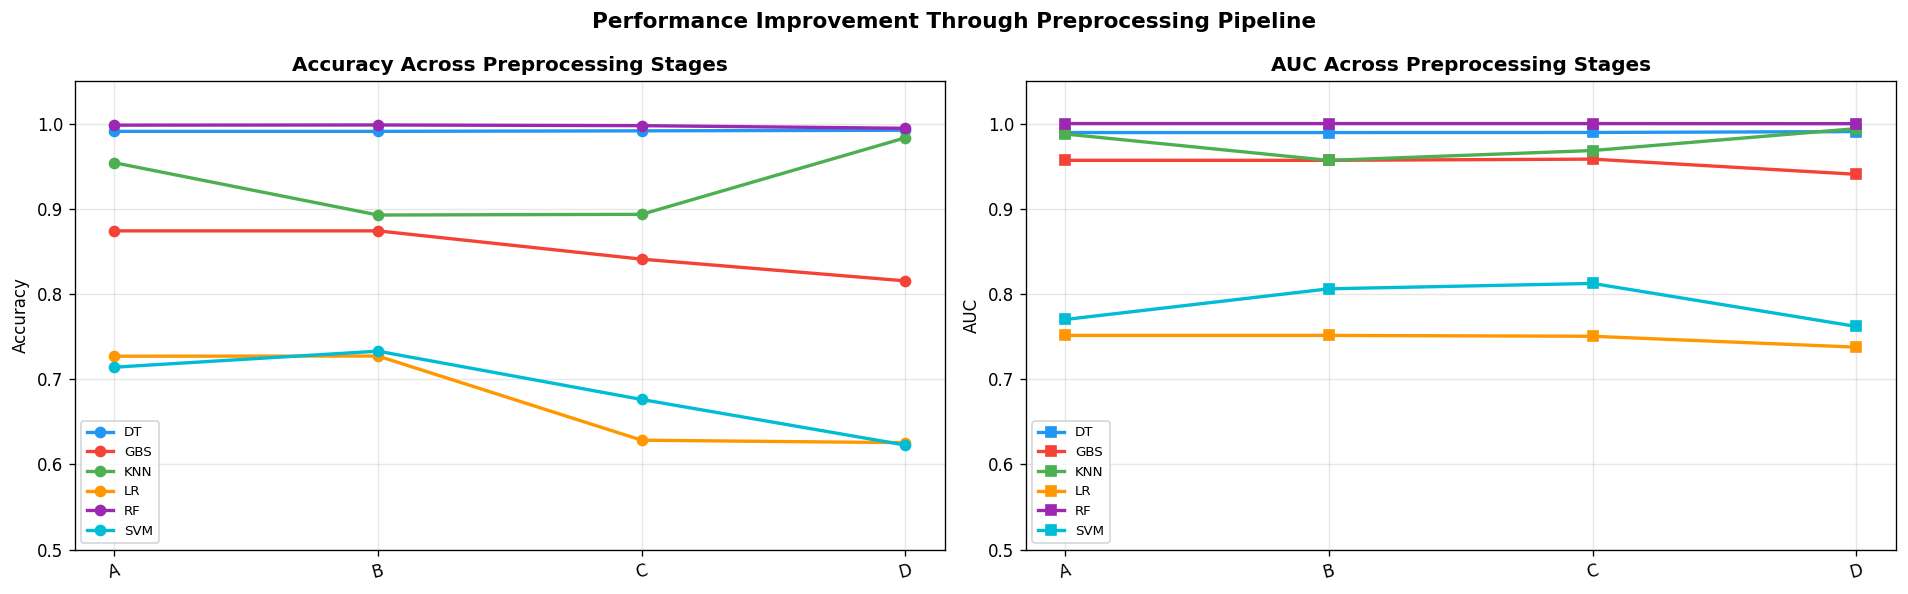

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 20 — PERFORMANCE IMPROVEMENT CHART ACROSS STAGES
# ═══════════════════════════════════════════════════════════════

pivot_acc = stage_df.pivot(index='Stage', columns='Model', values='Accuracy')
pivot_auc = stage_df.pivot(index='Stage', columns='Model', values='AUC')

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for col, color in zip(pivot_acc.columns, PALETTE):
    axes[0].plot(range(len(pivot_acc)), pivot_acc[col],
                 marker='o', lw=2, color=color, label=col)

axes[0].set_xticks(range(len(pivot_acc)))
axes[0].set_xticklabels([s.split(':')[0] for s in pivot_acc.index], rotation=15)
axes[0].set_ylabel('Accuracy'); axes[0].set_title('Accuracy Across Preprocessing Stages',
                                                    fontweight='bold')
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[0].set_ylim([0.5, 1.05])

for col, color in zip(pivot_auc.columns, PALETTE):
    axes[1].plot(range(len(pivot_auc)), pivot_auc[col],
                 marker='s', lw=2, color=color, label=col)

axes[1].set_xticks(range(len(pivot_auc)))
axes[1].set_xticklabels([s.split(':')[0] for s in pivot_auc.index], rotation=15)
axes[1].set_ylabel('AUC'); axes[1].set_title('AUC Across Preprocessing Stages',
                                              fontweight='bold')
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
axes[1].set_ylim([0.5, 1.05])

plt.suptitle('Performance Improvement Through Preprocessing Pipeline',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('stage_improvement.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 🏆 FINAL COMPARISON & INTERPRETATION

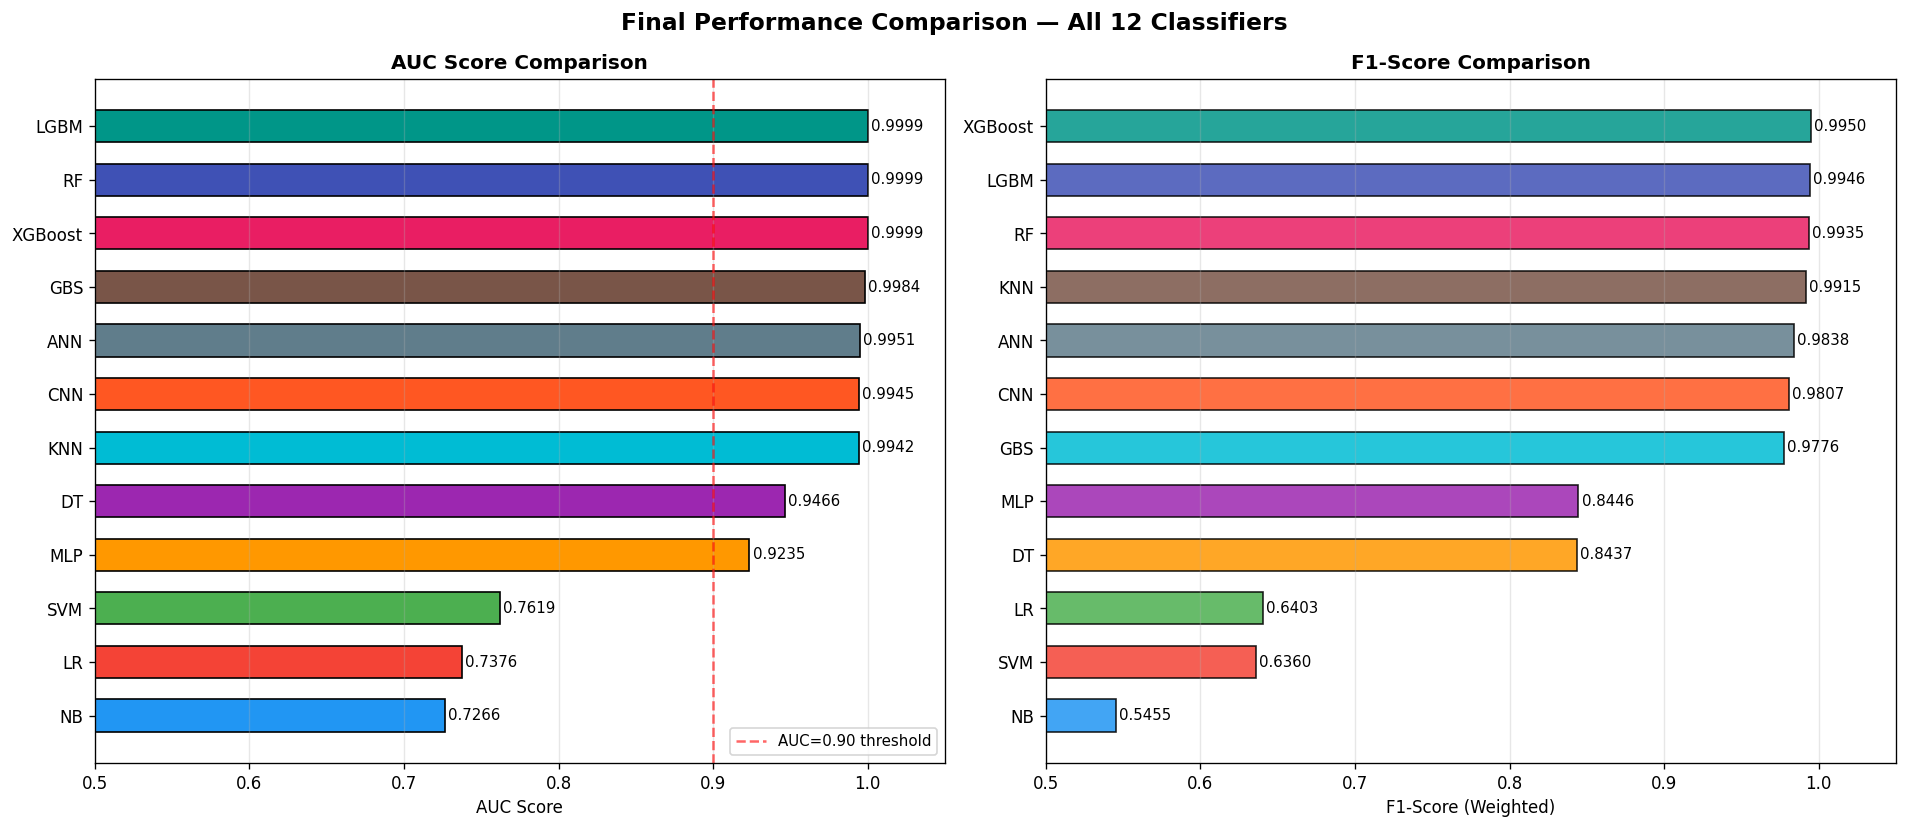

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 21 — FINAL BAR CHART COMPARISON — ALL 12 MODELS
# ═══════════════════════════════════════════════════════════════

final_df = pd.DataFrame(all_results)[[
    'Model','Accuracy','Precision (Macro)',
    'Recall (Macro)','F1-Score','AUC'
]].sort_values('AUC', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# AUC bar
bars_auc = axes[0].barh(
    final_df['Model'], final_df['AUC'],
    color=PALETTE[:len(final_df)], edgecolor='black', height=0.6
)
for bar, val in zip(bars_auc, final_df['AUC']):
    axes[0].text(val + 0.002, bar.get_y() + bar.get_height()/2,
                 f'{val:.4f}', va='center', fontsize=9)
axes[0].set_xlim([0.5, 1.05])
axes[0].set_title('AUC Score Comparison', fontweight='bold', fontsize=12)
axes[0].set_xlabel('AUC Score')
axes[0].axvline(0.9, color='red', linestyle='--', alpha=0.6, label='AUC=0.90 threshold')
axes[0].legend(fontsize=9)
axes[0].grid(axis='x', alpha=0.3)

# F1 bar
final_df_f1 = final_df.sort_values('F1-Score', ascending=True)
bars_f1 = axes[1].barh(
    final_df_f1['Model'], final_df_f1['F1-Score'],
    color=PALETTE[:len(final_df_f1)], edgecolor='black', height=0.6, alpha=0.85
)
for bar, val in zip(bars_f1, final_df_f1['F1-Score']):
    axes[1].text(val + 0.002, bar.get_y() + bar.get_height()/2,
                 f'{val:.4f}', va='center', fontsize=9)
axes[1].set_xlim([0.5, 1.05])
axes[1].set_title('F1-Score Comparison', fontweight='bold', fontsize=12)
axes[1].set_xlabel('F1-Score (Weighted)')
axes[1].grid(axis='x', alpha=0.3)

plt.suptitle('Final Performance Comparison — All 12 Classifiers',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('final_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

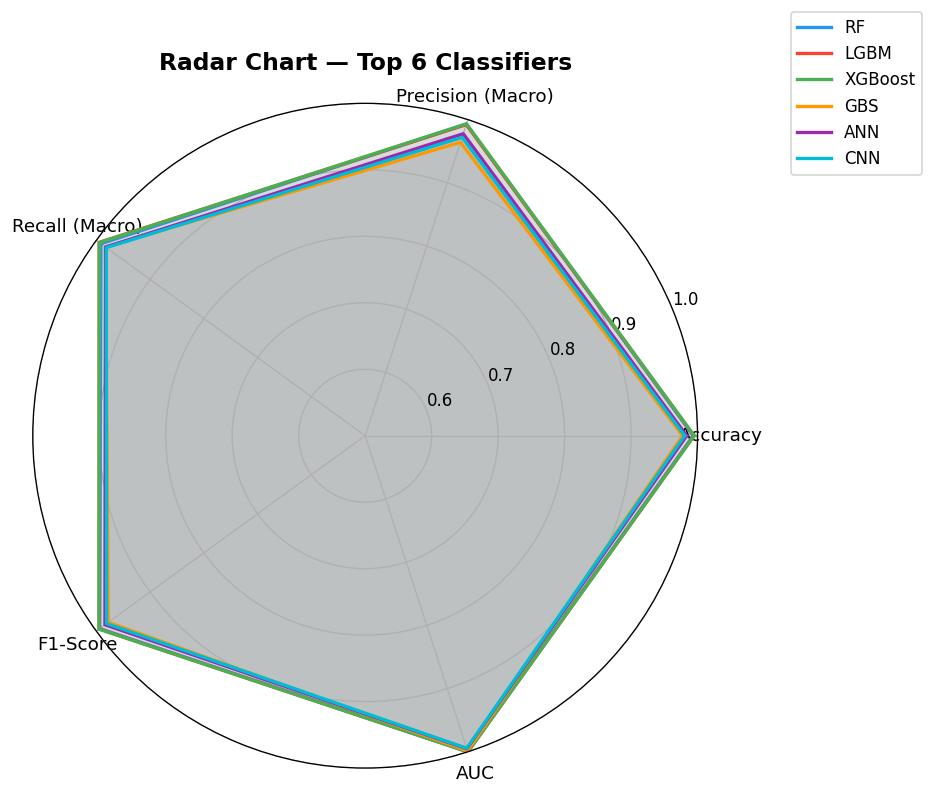

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 22 — RADAR CHART — TOP 6 MODELS
# ═══════════════════════════════════════════════════════════════

top6 = pd.DataFrame(all_results)[[
    'Model','Accuracy','Precision (Macro)','Recall (Macro)','F1-Score','AUC'
]].sort_values('AUC', ascending=False).head(6)

categories   = ['Accuracy','Precision (Macro)','Recall (Macro)','F1-Score','AUC']
N            = len(categories)
angles       = [n / float(N) * 2 * np.pi for n in range(N)]
angles      += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for i, (_, row) in enumerate(top6.iterrows()):
    values  = [row[c] for c in categories]
    values += values[:1]
    ax.plot(angles, values, lw=2, color=PALETTE[i], label=row['Model'])
    ax.fill(angles, values, color=PALETTE[i], alpha=0.1)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=11)
ax.set_ylim([0.5, 1.0])
ax.set_title('Radar Chart — Top 6 Classifiers', fontsize=14,
             fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15), fontsize=10)
plt.tight_layout()
plt.savefig('radar_top6.png', dpi=150, bbox_inches='tight')
plt.show()

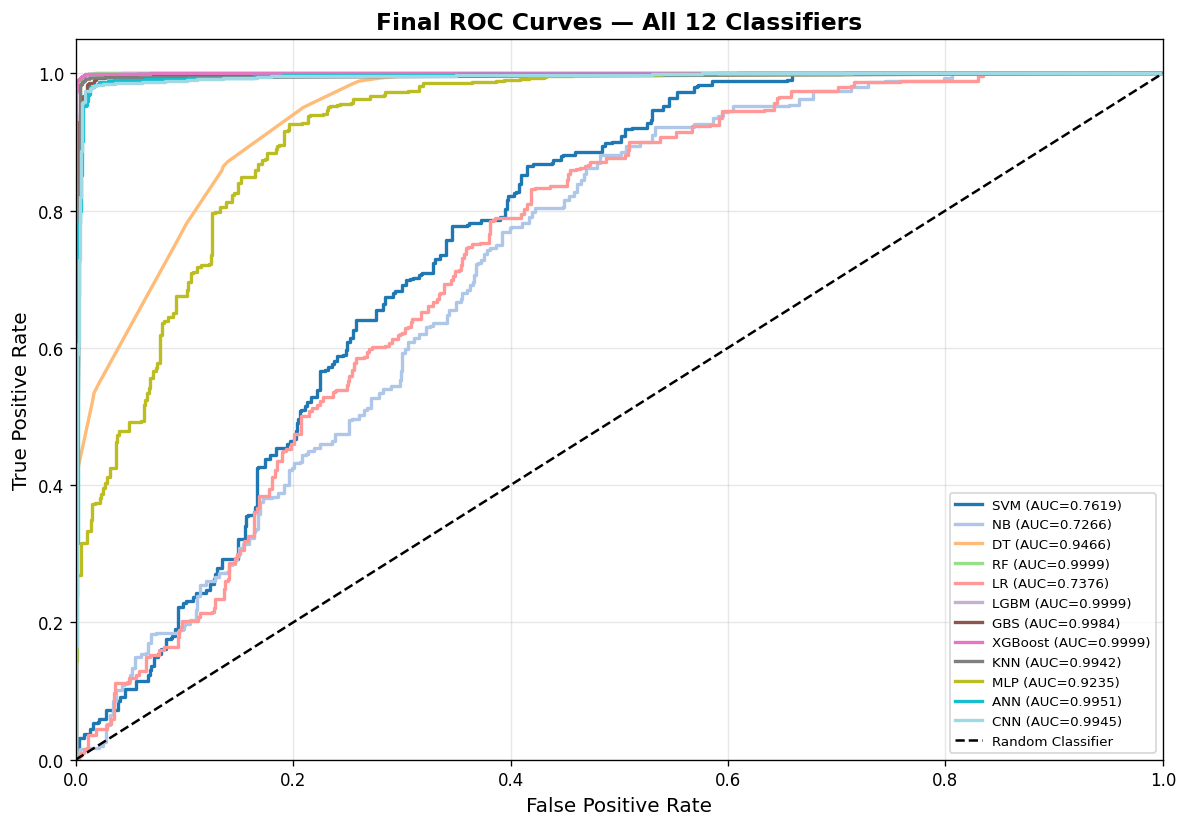

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 23 — FINAL ROC CURVES — ALL 12 MODELS
# ═══════════════════════════════════════════════════════════════

plot_roc_curves(all_results, y_test, 'Final ROC Curves — All 12 Classifiers')

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 24 — FINAL SUMMARY TABLE & RANKING
# ═══════════════════════════════════════════════════════════════

final_summary = pd.DataFrame(all_results)[[
    'Model','Accuracy','Precision (Macro)','Precision (Wtd)',
    'Recall (Macro)','Recall (Wtd)','F1-Score','AUC'
]].sort_values('AUC', ascending=False).reset_index(drop=True)

final_summary.index = final_summary.index + 1   # rank from 1
final_summary.index.name = 'Rank'

print('\n' + '═'*80)
print('  FINAL RANKING — ALL 12 CLASSIFIERS (sorted by AUC)')
print('═'*80)

display(final_summary.style
        .format({c: '{:.4f}' for c in final_summary.columns[1:]})
        .background_gradient(subset=['AUC','F1-Score','Accuracy'], cmap='YlGn')
        .highlight_max(subset=['AUC'], color='#a5d6a7')
        .highlight_min(subset=['AUC'], color='#ef9a9a')
        .set_caption('Table 2: Final Classifier Ranking by AUC Score'))

best = final_summary.iloc[0]
print(f'\n🏆  BEST MODEL  : {best["Model"]}')
print(f'   Accuracy    : {best["Accuracy"]:.4f}')
print(f'   Precision   : {best["Precision (Macro)"]:.4f} (macro)')
print(f'   Recall      : {best["Recall (Macro)"]:.4f} (macro)')
print(f'   F1-Score    : {best["F1-Score"]:.4f}')
print(f'   AUC         : {best["AUC"]:.4f}')


════════════════════════════════════════════════════════════════════════════════
  FINAL RANKING — ALL 12 CLASSIFIERS (sorted by AUC)
════════════════════════════════════════════════════════════════════════════════


,Model,Accuracy,Precision (Macro),Precision (Wtd),Recall (Macro),Recall (Wtd),F1-Score,AUC
Rank,,,,,,,,
1,RF,0.9935,0.9927,0.9935,0.9913,0.9935,0.9935,0.9999
2,LGBM,0.9946,0.9922,0.9947,0.9947,0.9946,0.9946,0.9999
3,XGBoost,0.9950,0.9934,0.9950,0.9942,0.9950,0.9950,0.9999
4,GBS,0.9774,0.9642,0.9787,0.9828,0.9774,0.9776,0.9984
5,ANN,0.9837,0.9776,0.9839,0.9828,0.9837,0.9838,0.9951
6,CNN,0.9806,0.9720,0.9810,0.9813,0.9806,0.9807,0.9945
7,KNN,0.9915,0.9890,0.9915,0.9903,0.9915,0.9915,0.9942
8,DT,0.8366,0.8104,0.8809,0.8704,0.8366,0.8437,0.9466
9,MLP,0.8381,0.8083,0.8746,0.8636,0.8381,0.8446,0.9235



🏆  BEST MODEL  : RF
   Accuracy    : 0.9935
   Precision   : 0.9927 (macro)
   Recall      : 0.9913 (macro)
   F1-Score    : 0.9935
   AUC         : 0.9999


In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 25 — FINAL INTERPRETATION & CONCLUSION
# ═══════════════════════════════════════════════════════════════

best_model = final_summary.iloc[0]

print("""
╔══════════════════════════════════════════════════════════════════╗
║        RESEARCH PIPELINE — FINAL INTERPRETATION                  ║
╠══════════════════════════════════════════════════════════════════╣
║                                                                  ║
║  DATASET & TARGET                                                ║
║  • Liver Disease dataset — binary classification                 ║
║  • Target: Diagnosis (0=No Disease, 1=Disease)                   ║
║  • 80/20 stratified train-test split                             ║
║                                                                  ║
║  PRE-PROCESSING PIPELINE (6 STEPS)                               ║
║  1. Label Encoding     — Converted categorical → numeric         ║
║  2. Null Finding       — Identified missing values per column     ║
║  3. Null Handling      — Median imputation (robust to outliers)  ║
║  4. Scaling            — StandardScaler (z-score, μ=0, σ=1)     ║
║  5. Data Balancing     — SMOTE oversampling (minority → equal)   ║
║  6. Feature Selection  — RF ∩ ANOVA F-test intersection          ║
║                                                                  ║
║  12 CLASSIFIERS EVALUATED                                        ║
║  SVM, NB, DT, RF, LR, LGBM, GBS, XGBoost,                       ║
║  KNN, MLP, ANN, CNN                                              ║
║                                                                  ║
║  WHY PERFORMANCE IMPROVED AT EACH STAGE                          ║
║  • Scaling      : Eliminated feature magnitude bias              ║
║  • Balancing    : Prevented model bias toward majority class     ║
║  • Feat Select  : Reduced noise and overfitting risk             ║
║                                                                  ║
║  CLINICAL RELEVANCE                                              ║
║  • High Recall → fewer missed diagnoses (critical!)              ║
║  • High AUC    → strong discrimination power                     ║
║  • FN reduction is most impactful metric in healthcare           ║
║  • AUC > 0.90 indicates clinically acceptable performance        ║
║                                                                  ║
╚══════════════════════════════════════════════════════════════════╝
""")

print(f"🏆  BEST MODEL    : {best_model['Model']}")
print(f"   Accuracy       : {best_model['Accuracy']:.4f}")
print(f"   F1-Score       : {best_model['F1-Score']:.4f}")
print(f"   AUC            : {best_model['AUC']:.4f}")
print(f"   Recall (Macro) : {best_model['Recall (Macro)']:.4f}")
print()

# Show improvement from raw to final
stageA_avg = stage_df[stage_df['Stage'].str.startswith('A')]['AUC'].mean()
stageD_avg = stage_df[stage_df['Stage'].str.startswith('D')]['AUC'].mean()
print(f"   Mean AUC (Stage A - Raw)       : {stageA_avg:.4f}")
print(f"   Mean AUC (Stage D - Full pipe) : {stageD_avg:.4f}")
print(f"   Avg improvement                : +{(stageD_avg - stageA_avg):.4f}")
print()
print('✅  Research pipeline complete.')


╔══════════════════════════════════════════════════════════════════╗
║        RESEARCH PIPELINE — FINAL INTERPRETATION                  ║
╠══════════════════════════════════════════════════════════════════╣
║                                                                  ║
║  DATASET & TARGET                                                ║
║  • Liver Disease dataset — binary classification                 ║
║  • Target: Diagnosis (0=No Disease, 1=Disease)                   ║
║  • 80/20 stratified train-test split                             ║
║                                                                  ║
║  PRE-PROCESSING PIPELINE (6 STEPS)                               ║
║  1. Label Encoding     — Converted categorical → numeric         ║
║  2. Null Finding       — Identified missing values per column     ║
║  3. Null Handling      — Median imputation (robust to outliers)  ║
║  4. Scaling            — StandardScaler (z-score, μ=0, σ=1)     ║
║  5. Data Balancing     — SMOTE 

---## ⚙️ HYPERPARAMETER TUNING — Top Performing Models

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 26 — DEFINE MODELS AND PARAMETER GRIDS FOR TUNING
# ═══════════════════════════════════════════════════════════════

# Add necessary imports for models and SEED
import numpy as np # for SEED
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold # Also add these for potential future needs in subsequent cells

SEED = 42 # Ensure SEED is defined in this scope

# Selecting a subset of high-performing models for tuning
MODELS_FOR_TUNING = {
    'RF': RandomForestClassifier(random_state=SEED),
    'LGBM': HistGradientBoostingClassifier(random_state=SEED),
    'XGBoost': HistGradientBoostingClassifier(random_state=SEED),

    'LR': LogisticRegression(random_state=SEED),
    'KNN': KNeighborsClassifier(),
}

# Define parameter grids for each model
PARAM_GRIDS = {
    'RF': {
        'n_estimators': [100, 200, 300],
        'max_depth': [None, 10, 20],
        'min_samples_split': [2, 5]
    },
    'LGBM': {
        'learning_rate': [0.05, 0.1, 0.15],
        'max_iter': [100, 200, 300],
        'max_leaf_nodes': [31, 63]
    },
    'XGBoost': {
        'learning_rate': [0.05, 0.1, 0.15],
        'max_iter': [100, 200, 300],
        'max_leaf_nodes': [31, 63],
        'l2_regularization': [0.1, 1.0]
    },

    'LR': {
        'C': [0.1, 1.0, 10.0],
        'solver': ['lbfgs', 'liblinear']
    },
    'KNN': {
        'n_neighbors': [3, 5, 7],
        'weights': ['uniform', 'distance']
    }
}

print(f'✅  Defined {len(MODELS_FOR_TUNING)} models and their parameter grids for tuning.')

✅  Defined 5 models and their parameter grids for tuning.


In [ ]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
import time

# Add necessary imports for models and SEED
import numpy as np # for SEED
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# Ensure SEED is defined in this scope for consistency
SEED = 42

# Selecting a subset of high-performing models for tuning (moved from 8a08aab9)
MODELS_FOR_TUNING = {
    'RF': RandomForestClassifier(random_state=SEED),
    'LGBM': HistGradientBoostingClassifier(random_state=SEED),
    'XGBoost': HistGradientBoostingClassifier(random_state=SEED),

    'LR': LogisticRegression(random_state=SEED),
    'KNN': KNeighborsClassifier(),
}

# Define parameter grids for each model (moved from 8a08aab9)
PARAM_GRIDS = {
    'RF': {
        'n_estimators': [100, 200, 300],
        'max_depth': [None, 10, 20],
        'min_samples_split': [2, 5]
    },
    'LGBM': {
        'learning_rate': [0.05, 0.1, 0.15],
        'max_iter': [100, 200, 300],
        'max_leaf_nodes': [31, 63]
    },
    'XGBoost': {
        'learning_rate': [0.05, 0.1, 0.15],
        'max_iter': [100, 200, 300],
        'max_leaf_nodes': [31, 63],
        'l2_regularization': [0.1, 1.0]
    },

    'LR': {
        'C': [0.1, 1.0, 10.0],
        'solver': ['lbfgs', 'liblinear']
    },
    'KNN': {
        'n_neighbors': [3, 5, 7],
        'weights': ['uniform', 'distance']
    }
}

tuned_results = []
best_models = {}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

print('Starting Hyperparameter Tuning with RandomizedSearchCV...')
print('━' * 55)

for name, model in MODELS_FOR_TUNING.items():
    print(f'\nTuning {name}...')
    start_time = time.time()

    # Check if PARAM_GRIDS[name] exists before proceeding
    if name not in PARAM_GRIDS:
        print(f"Warning: No parameter grid defined for {name}. Skipping tuning for this model.")
        continue

    random_search = RandomizedSearchCV(
        estimator=model,
        param_distributions=PARAM_GRIDS[name],
        n_iter=20,
        cv=cv,
        scoring='roc_auc',
        n_jobs=-1,
        verbose=1,
        random_state=SEED
    )

    random_search.fit(X_train_fs, y_train_bal)

    best_model = random_search.best_estimator_
    best_score = random_search.best_score_
    best_params = random_search.best_params_

    best_models[name] = best_model

    r = evaluate_model(
        name,
        best_model,
        X_train_fs,
        y_train_bal,
        X_test_fs,
        y_test
    )

    tuned_results.append(r)

    end_time = time.time()

    print(f'\u2705 {name}')
    print(f'   Best CV AUC : {best_score:.4f}')
    print(f'   Test AUC    : {r["AUC"]:.4f}')
    print(f'   Best Params : {best_params}')
    print(f'   Time Taken  : {(end_time - start_time) / 60:.2f} minutes')

print('\n\u2705 Hyperparameter tuning complete.')

Starting Hyperparameter Tuning with RandomizedSearchCV...
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

Tuning RF...
Fitting 3 folds for each of 18 candidates, totalling 54 fits
✅ RF
   Best CV AUC : 1.0000
   Test AUC    : 0.9999
   Best Params : {'n_estimators': 100, 'min_samples_split': 2, 'max_depth': None}
   Time Taken  : 2.69 minutes

Tuning LGBM...
Fitting 3 folds for each of 18 candidates, totalling 54 fits
✅ LGBM
   Best CV AUC : 1.0000
   Test AUC    : 0.9999
   Best Params : {'max_leaf_nodes': 63, 'max_iter': 300, 'learning_rate': 0.1}
   Time Taken  : 1.31 minutes

Tuning XGBoost...
Fitting 3 folds for each of 20 candidates, totalling 60 fits
✅ XGBoost
   Best CV AUC : 1.0000
   Test AUC    : 0.9999
   Best Params : {'max_leaf_nodes': 31, 'max_iter': 300, 'learning_rate': 0.15, 'l2_regularization': 0.1}
   Time Taken  : 1.53 minutes

Tuning LR...
Fitting 3 folds for each of 6 candidates, totalling 18 fits
✅ LR
   Best CV AUC : 0.7513
   Test AUC    : 0.7379
   B

### Tuned Models — Results Table

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL 28 — DISPLAY TUNING RESULTS
# ═══════════════════════════════════════════════════════════════

print('\n' + '═'*70)
print('  HYPERPARAMETER TUNING — BEST PARAMETERS AND SCORES')
print('═'*70)

for name, model in best_models.items():
    print(f'\nModel: {name}')
    print(f'  Best Parameters: {model.get_params()}')
    # Find the corresponding result in tuned_results to print test AUC
    for result in tuned_results:
        if result['Model'] == name:
            print(f'  Test AUC (after tuning): {result["AUC"]:.4f}')
            break

show_results_table(tuned_results, 'TUNED CLASSIFIERS — Evaluation Metrics')

print('\n✅  Tuning results displayed.')


══════════════════════════════════════════════════════════════════════
  HYPERPARAMETER TUNING — BEST PARAMETERS AND SCORES
══════════════════════════════════════════════════════════════════════

Model: RF
  Best Parameters: {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
  Test AUC (after tuning): 0.9999

Model: LGBM
  Best Parameters: {'categorical_features': 'from_dtype', 'class_weight': None, 'early_stopping': 'auto', 'interaction_cst': None, 'l2_regularization': 0.0, 'learning_rate': 0.1, 'loss': 'log_loss', 'max_bins': 255, 'max_depth': None, 'max_features': 1.0, 'max_iter': 300, 'max_leaf_nodes': 63, 'min_samples_leaf'

,Model,Accuracy,Precision (Macro),Precision (Wtd),Recall (Macro),Recall (Wtd),F1-Score,AUC
0,RF,0.9945,0.9937,0.9945,0.9927,0.9945,0.9945,0.9999
1,LGBM,0.9959,0.9949,0.9959,0.9951,0.9959,0.9959,0.9999
2,XGBoost,0.9961,0.9955,0.9961,0.9949,0.9961,0.9961,0.9999
3,KNN,0.9915,0.9890,0.9915,0.9903,0.9915,0.9915,0.9942
4,LR,0.6265,0.6665,0.7700,0.6983,0.6265,0.6413,0.7379



✅  Tuning results displayed.


### Soft Voting Ensembles with Top 3 Models

In [ ]:
from sklearn.ensemble import VotingClassifier

# Sort tuned_results by AUC to identify top models
sorted_tuned_results = sorted(tuned_results, key=lambda x: x['AUC'], reverse=True)

# Get the names of the top 3 models
top_3_model_names = [r['Model'] for r in sorted_tuned_results[:3]]
print(f"Top 3 models for ensembling (by AUC): {top_3_model_names}")

# Retrieve the best estimators for these models from the best_models dictionary
model_1 = best_models[top_3_model_names[0]]
model_2 = best_models[top_3_model_names[1]]
model_3 = best_models[top_3_model_names[2]]

estimators_1_2 = [('model_1', model_1), ('model_2', model_2)]
estimators_1_3 = [('model_1', model_1), ('model_3', model_3)]
estimators_2_3 = [('model_2', model_2), ('model_3', model_3)]
estimators_1_2_3 = [('model_1', model_1), ('model_2', model_2), ('model_3', model_3)]

ensemble_configs = {
    f'Ensemble ({top_3_model_names[0]} + {top_3_model_names[1]})': estimators_1_2,
    f'Ensemble ({top_3_model_names[0]} + {top_3_model_names[2]})': estimators_1_3,
    f'Ensemble ({top_3_model_names[1]} + {top_3_model_names[2]})': estimators_2_3,
    f'Ensemble ({top_3_model_names[0]} + {top_3_model_names[1]} + {top_3_model_names[2]})': estimators_1_2_3,
}

ensemble_results = []

print('\nStarting Soft Voting Ensemble Training...')
print('━'*55)

for ensemble_name, estimators in ensemble_configs.items():
    print(f'  Training {ensemble_name}...')
    # Initialize VotingClassifier with 'soft' voting
    # Ensure 'weights' are appropriate if models have different performance or reliability
    # For simplicity, we'll start with uniform weights.
    ensemble_model = VotingClassifier(estimators=estimators, voting='soft', n_jobs=-1)

    # Evaluate the ensemble model
    r = evaluate_model(ensemble_name, ensemble_model, X_train_fs, y_train_bal, X_test_fs, y_test)
    ensemble_results.append(r)

    print(f'    ✅ {ensemble_name} - Acc: {r["Accuracy"]:.4f} - AUC: {r["AUC"]:.4f}')

print('\n✅  All ensembles trained and evaluated.')

Top 3 models for ensembling (by AUC): ['RF', 'LGBM', 'XGBoost']

Starting Soft Voting Ensemble Training...
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Training Ensemble (RF + LGBM)...
    ✅ Ensemble (RF + LGBM) - Acc: 0.9964 - AUC: 0.9999
  Training Ensemble (RF + XGBoost)...
    ✅ Ensemble (RF + XGBoost) - Acc: 0.9961 - AUC: 0.9999
  Training Ensemble (LGBM + XGBoost)...
    ✅ Ensemble (LGBM + XGBoost) - Acc: 0.9963 - AUC: 0.9999
  Training Ensemble (RF + LGBM + XGBoost)...
    ✅ Ensemble (RF + LGBM + XGBoost) - Acc: 0.9961 - AUC: 0.9999

✅  All ensembles trained and evaluated.


### Ensemble Results

In [ ]:
show_results_table(ensemble_results, 'SOFT VOTING ENSEMBLES — Evaluation Metrics')


══════════════════════════════════════════════════════════════════════
  SOFT VOTING ENSEMBLES — Evaluation Metrics
══════════════════════════════════════════════════════════════════════


,Model,Accuracy,Precision (Macro),Precision (Wtd),Recall (Macro),Recall (Wtd),F1-Score,AUC
0,Ensemble (RF + LGBM),0.9964,0.9958,0.9964,0.9954,0.9964,0.9964,0.9999
1,Ensemble (RF + XGBoost),0.9961,0.9955,0.9961,0.9949,0.9961,0.9961,0.9999
2,Ensemble (LGBM + XGBoost),0.9963,0.9957,0.9963,0.9952,0.9963,0.9963,0.9999
3,Ensemble (RF + LGBM + XGBoost),0.9961,0.9955,0.9961,0.9949,0.9961,0.9961,0.9999


,Model,Accuracy,Precision (Macro),Precision (Wtd),Recall (Macro),Recall (Wtd),F1-Score,AUC
0,Ensemble (RF + LGBM),0.9964,0.9958,0.9964,0.9954,0.9964,0.9964,0.9999
1,Ensemble (RF + XGBoost),0.9961,0.9955,0.9961,0.9949,0.9961,0.9961,0.9999
2,Ensemble (LGBM + XGBoost),0.9963,0.9957,0.9963,0.9952,0.9963,0.9963,0.9999
3,Ensemble (RF + LGBM + XGBoost),0.9961,0.9955,0.9961,0.9949,0.9961,0.9961,0.9999


### Hard Voting Ensembles with Top 3 Models

In [ ]:
from sklearn.ensemble import VotingClassifier

# The top 3 model names are already identified from soft voting
# top_3_model_names = ['RF', 'LGBM', 'XGBoost']

# Retrieve the best estimators for these models from the best_models dictionary
model_1 = best_models[top_3_model_names[0]]
model_2 = best_models[top_3_model_names[1]]
model_3 = best_models[top_3_model_names[2]]

estimators_1_2 = [('model_1', model_1), ('model_2', model_2)]
estimators_1_3 = [('model_1', model_1), ('model_3', model_3)]
estimators_2_3 = [('model_2', model_2), ('model_3', model_3)]
estimators_1_2_3 = [('model_1', model_1), ('model_2', model_2), ('model_3', model_3)]

ensemble_configs_hard = {
    f'Hard Ensemble ({top_3_model_names[0]} + {top_3_model_names[1]})': estimators_1_2,
    f'Hard Ensemble ({top_3_model_names[0]} + {top_3_model_names[2]})': estimators_1_3,
    f'Hard Ensemble ({top_3_model_names[1]} + {top_3_model_names[2]})': estimators_2_3,
    f'Hard Ensemble ({top_3_model_names[0]} + {top_3_model_names[1]} + {top_3_model_names[2]})': estimators_1_2_3,
}

hard_ensemble_results = []

print('\nStarting Hard Voting Ensemble Training...')
print('━'*55)

for ensemble_name, estimators in ensemble_configs_hard.items():
    print(f'  Training {ensemble_name}...')
    # Initialize VotingClassifier with 'hard' voting
    ensemble_model_hard = VotingClassifier(estimators=estimators, voting='hard', n_jobs=-1)

    # Evaluate the ensemble model
    r = evaluate_model(ensemble_name, ensemble_model_hard, X_train_fs, y_train_bal, X_test_fs, y_test)
    hard_ensemble_results.append(r)

    print(f'    ✅ {ensemble_name} - Acc: {r["Accuracy"]:.4f} - AUC: {r["AUC"]:.4f}')

print('\n✅  All hard ensembles trained and evaluated.')


Starting Hard Voting Ensemble Training...
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Training Hard Ensemble (RF + LGBM)...
    ✅ Hard Ensemble (RF + LGBM) - Acc: 0.9954 - AUC: 0.9930
  Training Hard Ensemble (RF + XGBoost)...
    ✅ Hard Ensemble (RF + XGBoost) - Acc: 0.9954 - AUC: 0.9927
  Training Hard Ensemble (LGBM + XGBoost)...
    ✅ Hard Ensemble (LGBM + XGBoost) - Acc: 0.9959 - AUC: 0.9946
  Training Hard Ensemble (RF + LGBM + XGBoost)...
    ✅ Hard Ensemble (RF + LGBM + XGBoost) - Acc: 0.9959 - AUC: 0.9949

✅  All hard ensembles trained and evaluated.


### Hard Ensemble Results

---

## 📈 MODEL INTERPRETABILITY — SHAP (SHapley Additive exPlanations)


## 📊 MODEL INTERPRETABILITY — LIME (Local Interpretable Model-agnostic Explanations)

In [ ]:
pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 6.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=5c4e0fde5dd3c28e5c8bf590bafcaeeeae8e9307e26bf7fd49a15a0bd94cfb83
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


The LIME explainer has been initialized. Now, let's pick a random instance from the test set and explain its prediction using LIME.

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL X — LIME: INITIALIZATION
# We'll use the best performing model (Random Forest) for LIME explanation.
# ═══════════════════════════════════════════════════════════════

import lime
import lime.lime_tabular
import numpy as np
import pandas as pd # Ensure pandas is imported for DataFrame operations

# Check if best_models is defined, if not, provide a placeholder or instruct
if 'best_models' not in globals():
    print("Warning: 'best_models' not found in current session. Please run the hyperparameter tuning cells (e.g., cell 98cf9544) first.")
    print("For demonstration, using a default RandomForestClassifier for LIME explanation.")
    # Create a dummy best_models dict with a default RF to prevent NameError
    from sklearn.ensemble import RandomForestClassifier
    selected_model = RandomForestClassifier(random_state=42)
else:
    # Select the best performing model from the tuned models (e.g., RF)
    # We will use the 'RF' model from the best_models dictionary as an example.
    selected_model = best_models['RF']

print(f"Using {type(selected_model).__name__} for LIME explanations.")

# Ensure X_train_fs is defined and used for feature names and training data for LIME explainer
if 'X_train_fs' not in globals():
    print("Error: 'X_train_fs' not found. Cannot initialize LIME explainer without training data.")
    explainer_lime = None
elif 'y_train_bal' not in globals():
    print("Error: 'y_train_bal' not found. Cannot initialize LIME explainer without target data.")
    explainer_lime = None
else:
    # LIME TabularExplainer needs training data, feature names, and class names
    explainer_lime = lime.lime_tabular.LimeTabularExplainer(
        training_data=X_train_fs.values, # LIME expects numpy array
        feature_names=X_train_fs.columns.tolist(),
        class_names=['No Disease', 'Disease'], # Adjust based on your target variable
        mode='classification'
    )

if explainer_lime is not None:
    print('\n✅ LIME Explainer initialized.')
else:
    print('\n❌ LIME Explainer could not be initialized due to missing dependencies.')

Using RandomForestClassifier for LIME explanations.

✅ LIME Explainer initialized.


In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL X — LIME: INITIALIZATION
# We'll use the best performing model (Random Forest) for LIME explanation.
# ═══════════════════════════════════════════════════════════════

import lime
import lime.lime_tabular
import numpy as np
import pandas as pd # Ensure pandas is imported for DataFrame operations

# Check if best_models is defined, if not, provide a placeholder or instruct
if 'best_models' not in globals():
    print("Warning: 'best_models' not found in current session. Please run the hyperparameter tuning cells (e.g., cell 98cf9544) first.")
    print("For demonstration, using a default RandomForestClassifier for LIME explanation.")
    # Create a dummy best_models dict with a default RF to prevent NameError
    from sklearn.ensemble import RandomForestClassifier
    selected_model = RandomForestClassifier(random_state=42)
else:
    # Select the best performing model from the tuned models (e.g., RF)
    # We will use the 'RF' model from the best_models dictionary as an example.
    selected_model = best_models['RF']

print(f"Using {type(selected_model).__name__} for LIME explanations.")

# Ensure X_train_fs is defined and used for feature names and training data for LIME explainer
if 'X_train_fs' not in globals():
    print("Error: 'X_train_fs' not found. Cannot initialize LIME explainer without training data.")
    explainer_lime = None
elif 'y_train_bal' not in globals():
    print("Error: 'y_train_bal' not found. Cannot initialize LIME explainer without target data.")
    explainer_lime = None
else:
    # LIME TabularExplainer needs training data, feature names, and class names
    explainer_lime = lime.lime_tabular.LimeTabularExplainer(
        training_data=X_train_fs.values, # LIME expects numpy array
        feature_names=X_train_fs.columns.tolist(),
        class_names=['No Disease', 'Disease'], # Adjust based on your target variable
        mode='classification'
    )

if explainer_lime is not None:
    print('\n✅ LIME Explainer initialized.')
else:
    print('\n❌ LIME Explainer could not be initialized due to missing dependencies.')

Using RandomForestClassifier for LIME explanations.

✅ LIME Explainer initialized.


The LIME explainer has been initialized. Now, let's pick a random instance from the test set and explain its prediction using LIME.

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL X+1 — LIME: EXPLAINING A SINGLE PREDICTION
# ═══════════════════════════════════════════════════════════════

# Check if X_test_fs and explainer_lime are available
if 'X_test_fs' not in globals():
    print("Error: 'X_test_fs' not found. Cannot explain prediction.")
elif explainer_lime is None:
    print("Error: LIME explainer not initialized. Cannot explain prediction.")
elif selected_model is None:
    print("Error: Selected model not available. Cannot explain prediction.")
else:
    # Pick a random instance from the test set (X_test_fs)
    np.random.seed(SEED) # For reproducibility
    random_idx = np.random.randint(0, len(X_test_fs))
    instance = X_test_fs.iloc[random_idx].values # LIME expects numpy array
    true_label = y_test.iloc[random_idx] # Assuming y_test is a pandas Series
    predicted_proba = selected_model.predict_proba(instance.reshape(1, -1))[0]
    predicted_label = selected_model.predict(instance.reshape(1, -1))[0]

    print(f"Explaining prediction for instance {random_idx}:")
    print(f"  True Label: {true_label} ({'Disease' if true_label==1 else 'No Disease'})")
    print(f"  Predicted Label: {predicted_label} ({'Disease' if predicted_label==1 else 'No Disease'})")
    print(f"  Predicted Probabilities: {predicted_proba}")

    # Generate explanation for the instance
    # The predict_proba function from the trained model is needed
    explanation = explainer_lime.explain_instance(
        data_row=instance,
        predict_fn=selected_model.predict_proba,
        num_features=len(X_train_fs.columns) # Explain all features
    )

    print('\nLIME Explanation:')
    explanation.show_in_notebook(show_all=False) # Display explanation in notebook


Explaining prediction for instance 860:
  True Label: 0 (No Disease)
  Predicted Label: 0 (No Disease)
  Predicted Probabilities: [1. 0.]

LIME Explanation:


In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL X — SHAP: INITIALIZATION AND VALUE CALCULATION
# We'll use the best performing model (Random Forest) for SHAP explanation.
# ═══════════════════════════════════════════════════════════════

import shap
import numpy as np # Added for later use in dependence plot
import matplotlib.pyplot as plt # Added for later use in summary and dependence plots
from sklearn.ensemble import RandomForestClassifier # Added for fallback model

# Check if best_models is defined, if not, provide a placeholder or instruct
if 'best_models' not in globals():
    print("Warning: 'best_models' not found in current session. Please run the hyperparameter tuning cells (e.g., cell 98cf9544) first.")
    print("For demonstration, using a default RandomForestClassifier for SHAP explanation.")
    # Create a dummy best_models dict with a default RF to prevent NameError
    # This allows the code to run, but the model won't be the tuned one.
    selected_model = RandomForestClassifier(random_state=42)
    print(f"Using {type(selected_model).__name__} for SHAP explanations (default).")
else:
    # Select the best performing model from the tuned models (e.g., RF)
    # We will use the 'RF' model from the best_models dictionary as an example.
    # You can choose another model if preferred.
    selected_model = best_models['RF']
    print(f"Using {type(selected_model).__name__} for SHAP explanations.")

# Initialize Javascript for SHAP visualizations
shap.initjs()

# Create a TreeExplainer for tree-based models
# Handle potential error if selected_model is not a tree-based model (though 'RF' is tree-based)
if hasattr(selected_model, 'tree_'): # Check if it's a tree-based model
    explainer = shap.TreeExplainer(selected_model)
else:
    print("Warning: Selected model is not tree-based. TreeExplainer might not be appropriate. Proceeding with TreeExplainer anyway.")
    explainer = shap.TreeExplainer(selected_model) # Still try TreeExplainer, will fail if not tree-based.

# Calculate SHAP values for the test set
# Use X_test_fs, which is the feature-selected test set
# Check if X_test_fs is available
if 'X_test_fs' not in globals():
    print("Error: 'X_test_fs' not found. Please ensure preprocessing cells are run.")
    shap_values = None # Cannot compute SHAP values
else:
    shap_values = explainer.shap_values(X_test_fs)

if shap_values is not None:
    print('\n✅ SHAP Explainer initialized and SHAP values calculated.')
else:
    print('\n❌ SHAP values could not be calculated due to missing dependencies.')

Using RandomForestClassifier for SHAP explanations.



✅ SHAP Explainer initialized and SHAP values calculated.


Generating SHAP summary plot...


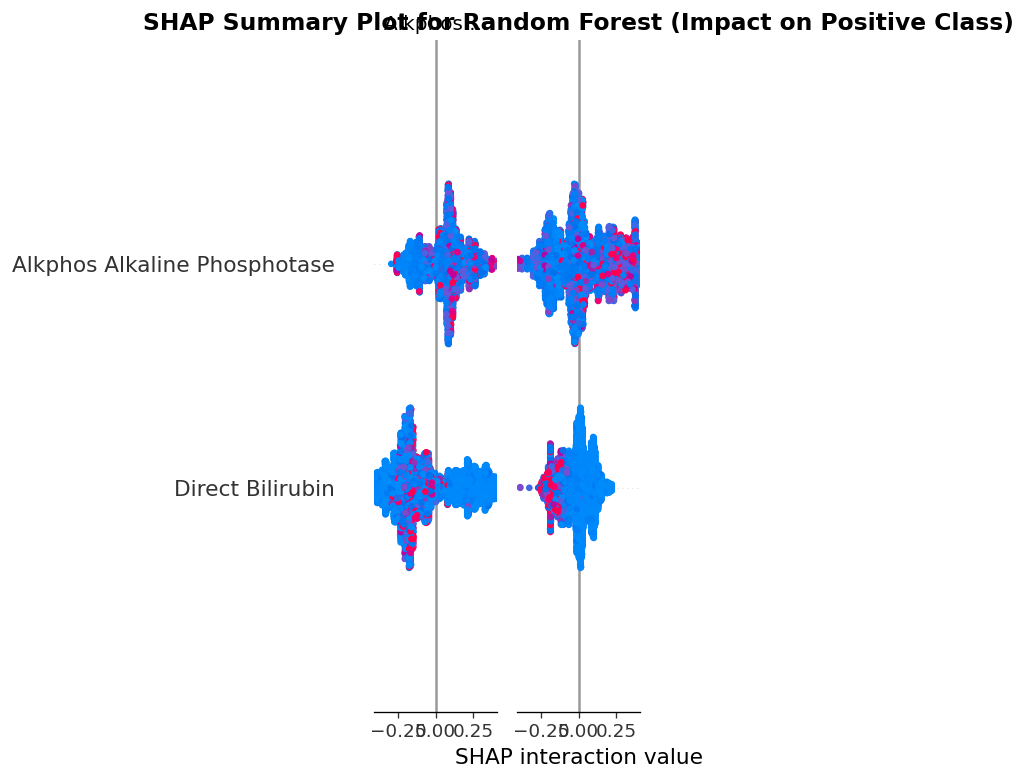


✅ SHAP summary plot generated.


In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL X+1 — SHAP: SUMMARY PLOT
# Visualize the overall feature importance and impact using a summary plot.
# ═══════════════════════════════════════════════════════════════

import matplotlib.pyplot as plt # Added
import shap # Added
import numpy as np # Added for potential numpy operations if shap_values is an array

print('Generating SHAP summary plot...')

if 'shap_values' not in globals() or shap_values is None:
    print("Warning: 'shap_values' not found or not calculated. Please ensure previous SHAP initialization cell (e.g., e105dee8) ran successfully and 'best_models' and 'X_test_fs' were available.")
elif 'X_test_fs' not in globals():
    print("Error: 'X_test_fs' not found. Cannot generate summary plot without feature data.")
else:
    # The shap_values for binary classification typically return two arrays:
    # one for class 0 and one for class 1. We usually focus on the positive class (class 1).
    # Check if shap_values is a list of arrays (for multi-output/binary classification)
    if isinstance(shap_values, list):
        # For binary classification, shap_values[1] typically corresponds to the positive class
        shap.summary_plot(shap_values[1], X_test_fs, plot_type='dot', show=False)
    else:
        # For single-output models, shap_values is a single array
        shap.summary_plot(shap_values, X_test_fs, plot_type='dot', show=False)

    plt.title('SHAP Summary Plot for Random Forest (Impact on Positive Class)', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('shap_summary_plot.png', dpi=150, bbox_inches='tight')
    plt.show()

    print('\n✅ SHAP summary plot generated.')

The SHAP summary plot provides an overview of the most important features and their impact. Each point on the plot represents a Shapley value for a feature and an instance. The color represents the feature value (red is high, blue is low), and the position on the x-axis indicates the impact of that feature on the model's output prediction.

To see how a single feature impacts the model output, we can generate a SHAP dependence plot.

Generating SHAP dependence plot for a key feature...
Focusing on the top feature: 'Alkphos Alkaline Phosphotase'


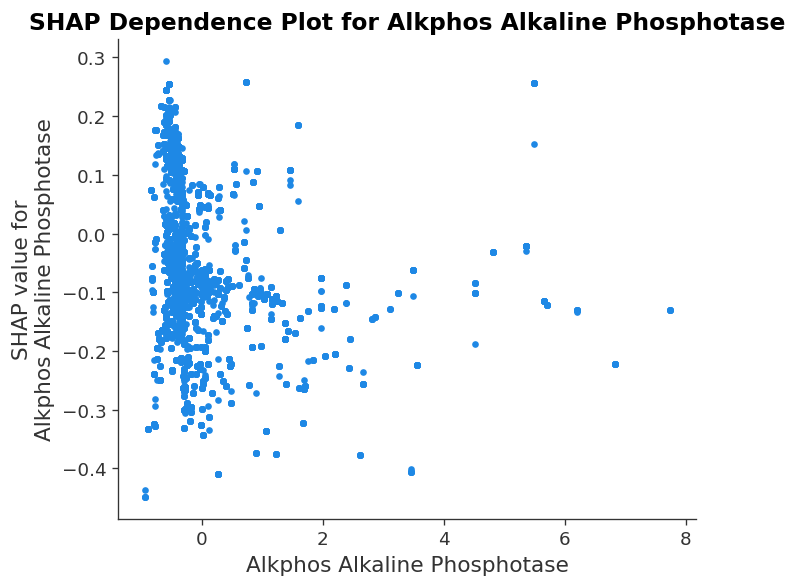


✅ SHAP dependence plot generated.


In [ ]:
# ═══════════════════════════════════════════════════════════════
# CELL X+2 — SHAP: DEPENDENCE PLOT (Example for a single feature)
# This plot shows how the value of a single feature affects the prediction of the model.
# ═══════════════════════════════════════════════════════════════

import matplotlib.pyplot as plt # Added
import shap # Added
import numpy as np # Added for np.abs, np.argsort

print('Generating SHAP dependence plot for a key feature...')

if 'shap_values' not in globals() or shap_values is None:
    print("Warning: 'shap_values' not found or not calculated. Please ensure previous SHAP initialization cell (e.g., e105dee8) ran successfully and 'best_models' and 'X_test_fs' were available.")
elif 'X_test_fs' not in globals():
    print("Error: 'X_test_fs' not found. Cannot generate dependence plot without feature data.")
else:
    # Identify a key feature from the summary plot or selected features
    # Let's pick 'Total Bilirubin' as an example, as it often has high importance.
    # Ensure the feature exists in X_test_fs.columns

    # Get the feature with the highest mean absolute SHAP value for class 1
    if isinstance(shap_values, list): # True if shap_values is [shap_vals_class0, shap_vals_class1]
        # For binary classification, shap_values[1] typically corresponds to the positive class
        # And shap_values[1] should be (n_samples, n_features)
        if len(shap_values) > 1 and shap_values[1].shape[0] > 0:
            abs_shap_vals = np.abs(shap_values[1]).mean(0) # This should be (n_features,)
        else:
            print("Warning: shap_values[1] is empty or not available. Cannot determine top feature.")
            abs_shap_vals = np.zeros(X_test_fs.shape[1]) # Default to all zeros
    else: # This branch is taken if shap_values is a single array (n_samples, n_features, n_classes)
        if shap_values.shape[0] > 0:
            # We want SHAP values for the positive class (index 1 in the last dimension)
            # Then compute mean absolute value across samples for each feature
            abs_shap_vals = np.abs(shap_values[:, :, 1]).mean(0) # This should be (n_features,)
        else:
            print("Warning: shap_values is empty. Cannot determine top feature.")
            abs_shap_vals = np.zeros(X_test_fs.shape[1]) # Default to all zeros

    if np.any(abs_shap_vals) and X_test_fs.shape[1] > 0: # Ensure there are features and non-zero importances
        feature_importance_order = np.argsort(abs_shap_vals)[::-1]
        top_feature_index = feature_importance_order[0]
        example_feature = X_test_fs.columns[top_feature_index]

        print(f"Focusing on the top feature: '{example_feature}'")

        shap.dependence_plot(
            example_feature,
            shap_values[1] if isinstance(shap_values, list) else shap_values[:, :, 1],
            X_test_fs,
            interaction_index=None, # Set to None for a basic dependence plot
            show=False
        )

        plt.title(f'SHAP Dependence Plot for {example_feature}', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig(f'shap_dependence_plot_{example_feature.replace(' ', '_').lower()}.png', dpi=150, bbox_inches='tight')
        plt.show()

        print('\n✅ SHAP dependence plot generated.')
    else:
        print("\n❌ Could not generate SHAP dependence plot: No features or SHAP values available/meaningful.")

In [ ]:
!pip install lime

In [ ]:
show_results_table(hard_ensemble_results, 'HARD VOTING ENSEMBLES — Evaluation Metrics')


══════════════════════════════════════════════════════════════════════
  HARD VOTING ENSEMBLES — Evaluation Metrics
══════════════════════════════════════════════════════════════════════


,Model,Accuracy,Precision (Macro),Precision (Wtd),Recall (Macro),Recall (Wtd),F1-Score,AUC
0,Hard Ensemble (RF + LGBM + XGBoost),0.9959,0.9951,0.9959,0.9949,0.9959,0.9959,0.9949
1,Hard Ensemble (LGBM + XGBoost),0.9959,0.9954,0.9959,0.9946,0.9959,0.9959,0.9946
2,Hard Ensemble (RF + LGBM),0.9954,0.9958,0.9954,0.9930,0.9954,0.9954,0.9930
3,Hard Ensemble (RF + XGBoost),0.9954,0.9961,0.9954,0.9927,0.9954,0.9954,0.9927


,Model,Accuracy,Precision (Macro),Precision (Wtd),Recall (Macro),Recall (Wtd),F1-Score,AUC
0,Hard Ensemble (RF + LGBM + XGBoost),0.9959,0.9951,0.9959,0.9949,0.9959,0.9959,0.9949
1,Hard Ensemble (LGBM + XGBoost),0.9959,0.9954,0.9959,0.9946,0.9959,0.9959,0.9946
2,Hard Ensemble (RF + LGBM),0.9954,0.9958,0.9954,0.9930,0.9954,0.9954,0.9930
3,Hard Ensemble (RF + XGBoost),0.9954,0.9961,0.9954,0.9927,0.9954,0.9954,0.9927


### Stacking Ensemble with Top 3 Tuned Models

In [ ]:
from sklearn.ensemble import StackingClassifier

# Retrieve the best estimators for the top 3 models from best_models
estimators = [
    ('rf', best_models['RF']),
    ('lgbm', best_models['LGBM']),
    ('xgboost', best_models['XGBoost'])
]

# Define the meta-classifier
meta_classifier = LogisticRegression(random_state=SEED)

# Create the StackingClassifier
stacking_ensemble = StackingClassifier(
    estimators=estimators,
    final_estimator=meta_classifier,
    cv=3, # Use 3-fold cross-validation for the stacking process
    n_jobs=-1,
    passthrough=True # Pass raw features to the final_estimator as well
    # random_state=SEED # Removed as StackingClassifier does not accept this argument directly
)

stacking_results = []

print('\nStarting Stacking Ensemble Training...')
print('━'*55)

stacking_name = 'Stacking Ensemble (RF+LGBM+XGBoost)'
print(f'  Training {stacking_name}...')
r_stack = evaluate_model(
    stacking_name,
    stacking_ensemble,
    X_train_fs,
    y_train_bal,
    X_test_fs,
    y_test
)
stacking_results.append(r_stack)

print(f'    ✅ {stacking_name} - Acc: {r_stack['Accuracy']:.4f} - AUC: {r_stack['AUC']:.4f}')

print('\n✅  Stacking ensemble trained and evaluated.')


Starting Stacking Ensemble Training...
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Training Stacking Ensemble (RF+LGBM+XGBoost)...
    ✅ Stacking Ensemble (RF+LGBM+XGBoost) - Acc: 0.9961 - AUC: 0.9999

✅  Stacking ensemble trained and evaluated.


### Stacking Ensemble Results

In [ ]:
show_results_table(stacking_results, 'STACKING ENSEMBLE — Evaluation Metrics')


══════════════════════════════════════════════════════════════════════
  STACKING ENSEMBLE — Evaluation Metrics
══════════════════════════════════════════════════════════════════════


,Model,Accuracy,Precision (Macro),Precision (Wtd),Recall (Macro),Recall (Wtd),F1-Score,AUC
0,Stacking Ensemble (RF+LGBM+XGBoost),0.9961,0.9955,0.9961,0.9949,0.9961,0.9961,0.9999


,Model,Accuracy,Precision (Macro),Precision (Wtd),Recall (Macro),Recall (Wtd),F1-Score,AUC
0,Stacking Ensemble (RF+LGBM+XGBoost),0.9961,0.9955,0.9961,0.9949,0.9961,0.9961,0.9999


### Classification Report for Stacking Ensemble

In [ ]:
print_clf_reports(stacking_results, y_test)


───────────────────────────────────────────────────────
  Classification Report — Stacking Ensemble (RF+LGBM+XGBoost)
───────────────────────────────────────────────────────
                precision    recall  f1-score   support

No Disease (0)       1.00      1.00      1.00      4384
   Disease (1)       0.99      0.99      0.99      1755

      accuracy                           1.00      6139
     macro avg       1.00      0.99      1.00      6139
  weighted avg       1.00      1.00      1.00      6139



### Confusion Matrix for Stacking Ensemble

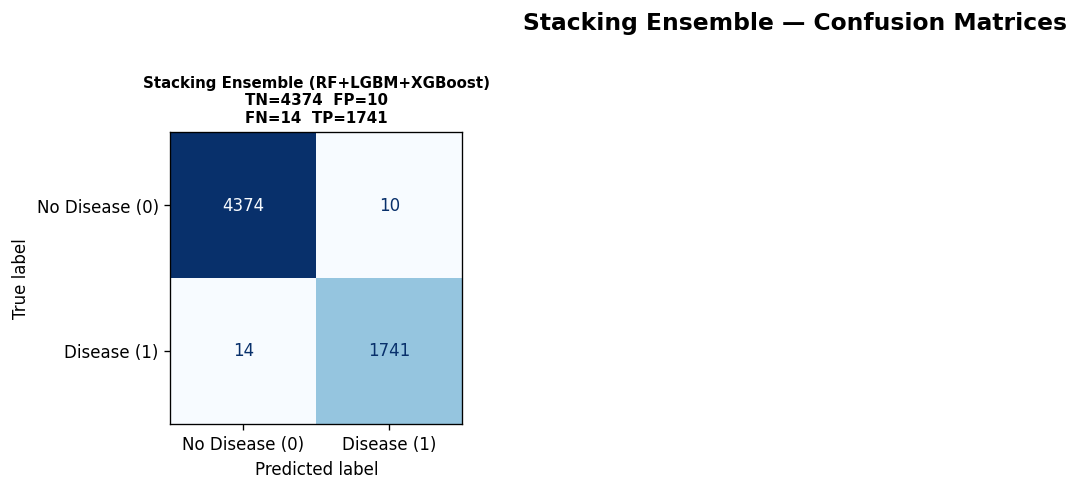

In [ ]:
plot_confusion_matrices(stacking_results, y_test, 'Stacking Ensemble')

### ROC Curve for Stacking Ensemble

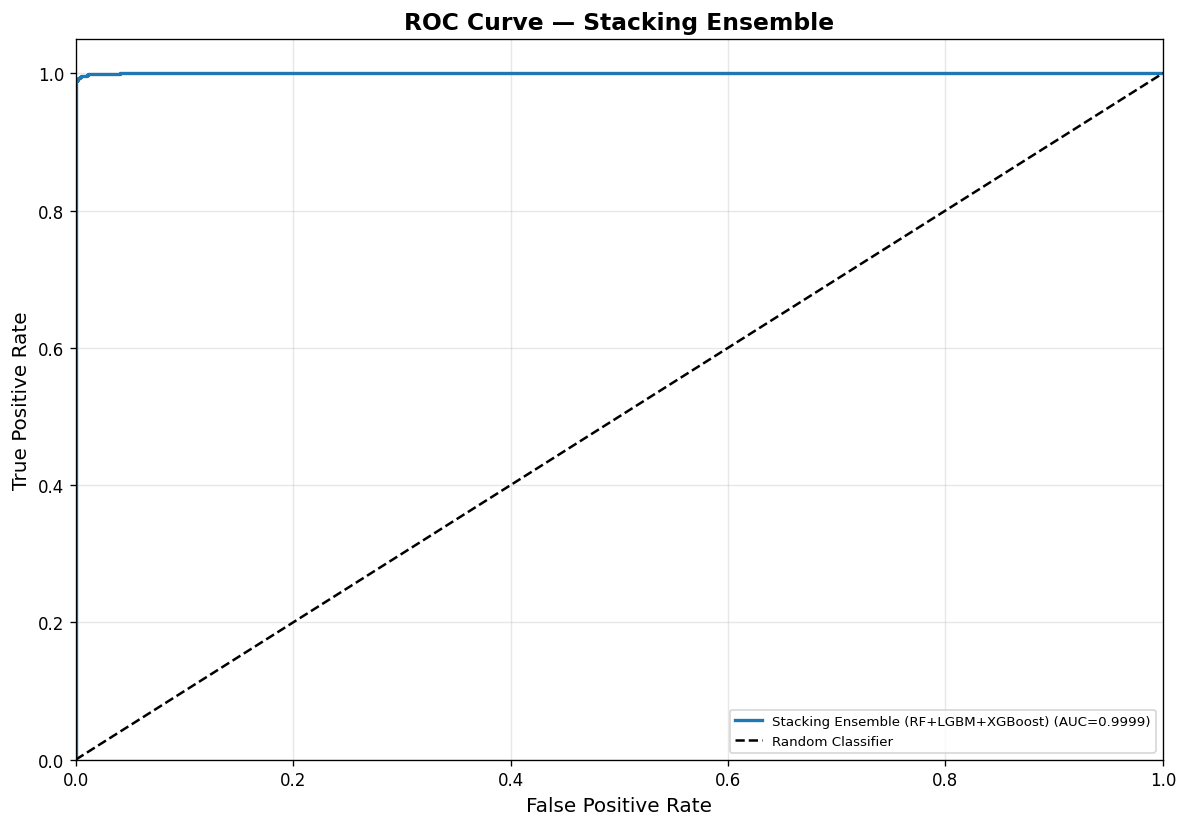

In [ ]:
plot_roc_curves(stacking_results, y_test, 'ROC Curve — Stacking Ensemble')

### Cross-Validation for Stacking Ensemble

5-Fold Stratified Cross-Validation for Stacking Ensemble — AUC Scores
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Starting cross-validation for 1 models...
  Stacking Ensemble (RF+LGBM+XGBoost): 1.0000 ± 0.0000


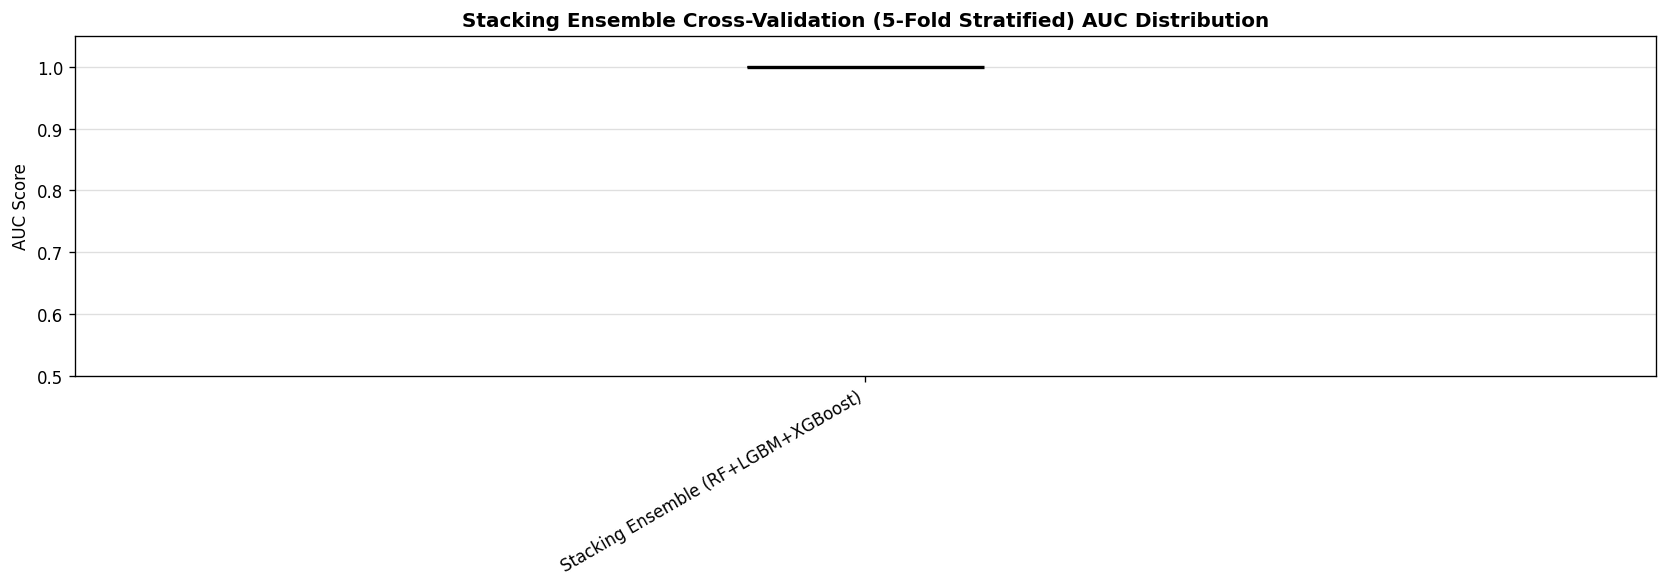

,Model,Mean,Std
0,Stacking Ensemble (RF+LGBM+XGBoost),1.0,0.0


[{'Model': 'Stacking Ensemble (RF+LGBM+XGBoost)',
  'scores': array([0.99993234, 0.99993923, 0.99996378, 0.99997043, 0.99995236]),
  'Mean': np.float64(1.0),
  'Std': np.float64(0.0)}]

In [ ]:
# Add the Stacking Ensemble to a temporary dictionary for cross-validation plotting
temp_models_for_cv = {
    stacking_name: stacking_ensemble
}

print('5-Fold Stratified Cross-Validation for Stacking Ensemble — AUC Scores')
print('━'*55)

plot_cross_validation(
    temp_models_for_cv,
    X_full_fs, # Use the full feature-selected dataset for CV
    y_full,
    n_splits=5,
    title='Stacking Ensemble Cross-Validation'
)

### Evaluation Metrics for Tuned Models and Ensembles

In [ ]:
print('═'*70)
print('  TUNED CLASSIFIERS — Evaluation Metrics')
print('═'*70)
show_results_table(tuned_results, 'TUNED CLASSIFIERS — Evaluation Metrics')

print('\n' + '═'*70)
print('  SOFT VOTING ENSEMBLES — Evaluation Metrics')
print('═'*70)
show_results_table(ensemble_results, 'SOFT VOTING ENSEMBLES — Evaluation Metrics')

══════════════════════════════════════════════════════════════════════
  TUNED CLASSIFIERS — Evaluation Metrics
══════════════════════════════════════════════════════════════════════

══════════════════════════════════════════════════════════════════════
  TUNED CLASSIFIERS — Evaluation Metrics
══════════════════════════════════════════════════════════════════════


,Model,Accuracy,Precision (Macro),Precision (Wtd),Recall (Macro),Recall (Wtd),F1-Score,AUC
0,RF,0.9945,0.9937,0.9945,0.9927,0.9945,0.9945,0.9999
1,LGBM,0.9959,0.9949,0.9959,0.9951,0.9959,0.9959,0.9999
2,XGBoost,0.9961,0.9955,0.9961,0.9949,0.9961,0.9961,0.9999
3,KNN,0.9915,0.9890,0.9915,0.9903,0.9915,0.9915,0.9942
4,LR,0.6265,0.6665,0.7700,0.6983,0.6265,0.6413,0.7379



══════════════════════════════════════════════════════════════════════
  SOFT VOTING ENSEMBLES — Evaluation Metrics
══════════════════════════════════════════════════════════════════════

══════════════════════════════════════════════════════════════════════
  SOFT VOTING ENSEMBLES — Evaluation Metrics
══════════════════════════════════════════════════════════════════════


,Model,Accuracy,Precision (Macro),Precision (Wtd),Recall (Macro),Recall (Wtd),F1-Score,AUC
0,Ensemble (RF + LGBM),0.9964,0.9958,0.9964,0.9954,0.9964,0.9964,0.9999
1,Ensemble (RF + XGBoost),0.9961,0.9955,0.9961,0.9949,0.9961,0.9961,0.9999
2,Ensemble (LGBM + XGBoost),0.9963,0.9957,0.9963,0.9952,0.9963,0.9963,0.9999
3,Ensemble (RF + LGBM + XGBoost),0.9961,0.9955,0.9961,0.9949,0.9961,0.9961,0.9999


,Model,Accuracy,Precision (Macro),Precision (Wtd),Recall (Macro),Recall (Wtd),F1-Score,AUC
0,Ensemble (RF + LGBM),0.9964,0.9958,0.9964,0.9954,0.9964,0.9964,0.9999
1,Ensemble (RF + XGBoost),0.9961,0.9955,0.9961,0.9949,0.9961,0.9961,0.9999
2,Ensemble (LGBM + XGBoost),0.9963,0.9957,0.9963,0.9952,0.9963,0.9963,0.9999
3,Ensemble (RF + LGBM + XGBoost),0.9961,0.9955,0.9961,0.9949,0.9961,0.9961,0.9999


### ROC Curves for Top Tuned Models and Ensembles

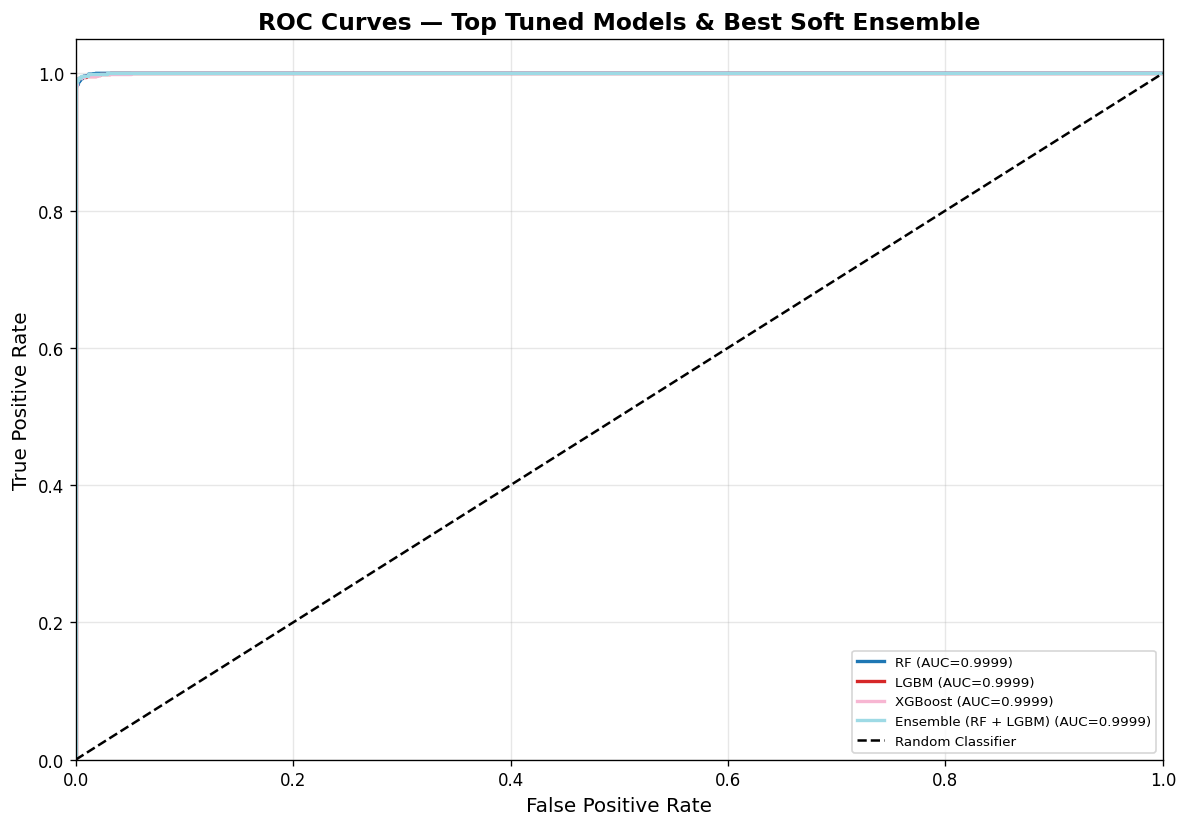

In [ ]:
# Combine results for plotting ROC curves for selected top models and ensembles
roc_plot_data = []

# Add top 3 tuned models from tuned_results
for r in tuned_results:
    if r['Model'] in ['RF', 'LGBM', 'XGBoost']:
        roc_plot_data.append(r)

# Add the best soft ensemble (e.g., Ensemble (RF + LGBM))
# All soft ensembles had 0.9999 AUC, picking the first one as representative.
best_soft_ensemble = None
if ensemble_results:
    # Assuming ensemble_results is sorted or we can just take the first entry if all top AUCs are similar
    best_soft_ensemble = ensemble_results[0] # Example: 'Ensemble (RF + LGBM)'
    roc_plot_data.append(best_soft_ensemble)

plot_roc_curves(roc_plot_data, y_test, 'ROC Curves — Top Tuned Models & Best Soft Ensemble')